# 08 · Flow matching and rectified flow: the modern, simpler formulation

Diffusion models learn a *score* and integrate a reverse-time SDE (or its probability-flow ODE).
**Flow matching** skips the SDE altogether: pick a simple path from data to noise, and regress a
neural *velocity field* whose ODE carries noise back to data. This is the formulation behind
Stable Diffusion 3, Flux and many recent video, audio and robot-policy models. We derive it from
scratch, check every step against an exact ground truth, and then show that it is the same
object as a diffusion model, seen in different coordinates.

**You will learn:**
- why regressing on the per-sample velocity $\varepsilon - x_0$ learns the *marginal* velocity
  $v(x,t)=\mathbb E[\varepsilon - x_0\mid x_t=x]$ (a posterior mean again, like Tweedie), and why that velocity transports noise to data;
- the closed-form velocity field of a Gaussian mixture, which we use as ground truth;
- how to train a flow-matching model in ~20 lines and sample it with Euler / Heun, and how it compares to DDPM/DDIM at equal cost;
- why the learned trajectories are curved, and how to measure straightness;
- the exact dictionary between flow matching and diffusion ($\hat x_0$, $\hat\varepsilon$, $v$, SNR, loss weighting; DDIM *is* Euler);
- two ways to straighten the flow for 1–2-step sampling: **reflow** (rectified flow) and **mini-batch optimal-transport** couplings;
- the practical knobs used in large models: timestep distributions, step counts, guidance on velocities.

**Prerequisites:** 01 (forward process), 02 (DDPM), 03 (score matching, Tweedie), 04 (DDIM / probability-flow ODE); 06 (guidance) for the last section.

**Runtime:** about 5–7 min on a laptop CPU (five small MLPs of roughly 15 s to 1 min each, plus sampling and the exact-velocity computations); about 2–4 min on a GPU (tiny MLPs, so a GPU helps less than usual).

In [1]:
import copy
import math
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy.optimize import linear_sum_assignment

import dmtools as dm

device = dm.get_device(verbose=True)
FAST = dm.fast_mode()  # automated smoke-test switch, leave as is
dm.seed_everything(0)
plt.rcParams.update({"figure.dpi": 100, "font.size": 9, "axes.titlesize": 10,
                     "axes.labelsize": 9, "legend.fontsize": 8})

# --- budget knobs (FAST mode only checks that every code path runs) ---
STEPS = 300 if FAST else 5000           # optimisation steps for each model trained from scratch
BATCH, LR = 256, 1e-3
N_TRAIN = 5_000 if FAST else 50_000     # size of the training set
N_EVAL = 500 if FAST else 2000          # samples used for every MMD estimate
N_PLOT = 600                            # points drawn per scatter panel (keeps the notebook small)
NFES = [1, 2, 8] if FAST else [1, 2, 4, 8, 16, 32, 64]   # numbers of function evaluations to sweep

# one colour per method, used in every figure
COL = dict(data="0.75", exact="k", fm="tab:blue", ddpm="tab:orange", reflow="tab:green", ot="tab:purple")

Using device: cpu


**Conventions for this notebook (they differ from the discrete-time DDPM notebooks!).** Time is continuous,
$t\in[0,1]$, with **data at $t=0$ and noise at $t=1$** (the rectified-flow / SD3 convention; notebook 04's
continuous-time VP-SDE runs in the same direction, but along the path $\sqrt{\bar\alpha(t)}\,x_0+\sqrt{1-\bar\alpha(t)}\,\varepsilon$):

$$x_t = (1-t)\,x_0 + t\,\varepsilon,\qquad x_0\sim p_{\rm data},\ \ \varepsilon\sim\mathcal N(0,I).$$

We sample by integrating an ODE *backwards*, from $t=1$ to $t=0$. (Lipman et al. 2023 and several
codebases use the opposite direction, noise at $t=0$ and data at $t=1$, which flips the sign of the
velocity: always check the convention when reading papers or code.) The networks are
`dm.MLPDenoiser`s, whose sinusoidal time embedding was designed for the integer steps
$0,\dots,999$ of earlier notebooks, so **we feed them $1000\,t$**. (Gotcha: feeding
$t\in[0,1]$ directly "works", but then all but the fastest few embedding features are almost
constant and the network loses fine resolution in $t$, see notebook 02 §3a. On a smooth 2-D
problem that costs little (notebook 02, Exercise 6), but there is no reason to give it away.)
In this notebook $v$ always means the flow **velocity** $\varepsilon-x_0$ (or its posterior mean), not the
"$v$-prediction" target $\sqrt{\bar\alpha}\,\varepsilon-\sqrt{1-\bar\alpha}\,x_0$ of notebooks 02 and 10; Section 5 relates the two.

Our data is the 8-component 2-D Gaussian mixture `dm.default_gmm()`, chosen because every
quantity in this notebook (densities, posterior means, velocities) has a closed form for it.

In [2]:
def time_input(t):
    """Map flow time t in [0, 1] to the input range the MLP's sinusoidal embedding expects."""
    return 1000.0 * t


gmm = dm.default_gmm()
g = torch.Generator().manual_seed(0)
data = gmm.sample(N_TRAIN, generator=g)          # fixed training set (CPU)
test = gmm.sample(N_EVAL, generator=g)           # held-out samples for evaluation
data_dev = data.to(device)

# MMD between two independent sets of true samples = the best score any sampler can hope for
MMD_FLOOR = dm.mmd_rbf(gmm.sample(N_EVAL, generator=g), test)
print(f"training set {tuple(data.shape)}, mean {data.mean(0).numpy().round(2)}, std {data.std(0).numpy().round(2)}")
print(f"MMD between two independent sets of {N_EVAL} true samples (noise floor): {MMD_FLOOR:.4f}")

training set (50000, 2), mean [-0.   -0.01], std [1.03 1.03]
MMD between two independent sets of 2000 true samples (noise floor): 0.0039


## 1 · From scores to velocities

**Intuition.** A diffusion model learns the score $\nabla\log p_t$ and then needs a
(stochastic or probability-flow) differential equation built from it to generate.
Flow matching asks a more direct question: *which velocity field $v(x,t)$ moves a cloud of
Gaussian noise into the data distribution?* If we had it, sampling would just be
"draw $x_1\sim\mathcal N(0,I)$ and integrate $\dot x = v(x,t)$ from $t=1$ to $t=0$".

**The continuity equation.** A velocity field $v$ moves a density $p_t$ around without
creating or destroying mass, which is expressed by

$$\partial_t p_t(x) + \nabla\cdot\big(p_t(x)\,v(x,t)\big) = 0 .$$

So we want *some* $v$ that satisfies this for the path $p_t$ = law of $x_t=(1-t)x_0+t\varepsilon$.

**Each pair moves in a straight line.** For a fixed pair $(x_0,\varepsilon)$ the point
$x_t$ travels at constant velocity $\dot x_t = \varepsilon - x_0$. Many pairs pass through the
same location $x$ at time $t$, with different velocities; the natural guess is their average:

$$v(x,t) \;=\; \mathbb E\left[\varepsilon - x_0 \,\middle|\, x_t = x\right].$$

**Claim: this $v$ satisfies the continuity equation.** Take any smooth test function $\varphi$ with compact support:

$$\frac{d}{dt}\mathbb E[\varphi(x_t)]
= \mathbb E\big[\nabla\varphi(x_t)^\top(\varepsilon - x_0)\big]
\overset{\text{tower}}{=} \mathbb E\big[\nabla\varphi(x_t)^\top\,\mathbb E[\varepsilon - x_0\mid x_t]\big]
= \int \nabla\varphi(x)^\top v(x,t)\,p_t(x)\,dx
= -\int \varphi(x)\,\nabla\cdot\big(p_t v\big)(x)\,dx ,$$

(the last step integrates by parts). The left side is $\int\varphi\,\partial_t p_t\,dx$, and since this holds for every $\varphi$,
$\partial_t p_t = -\nabla\cdot(p_t v)$. Under mild regularity (a Lipschitz $v$), the ODE
$\dot x = v(x,t)$ started from $p_1=\mathcal N(0,I)$ therefore has marginal $p_t$ at every time,
and in particular produces $p_0 = p_{\rm data}$ at $t=0$. Note that the ODE paths are *not* the
straight lines: each particle follows the *averaged* velocity (Section 4).

**The training objective.** We cannot regress on $v$ directly (it is an intractable
conditional expectation), but we *can* regress on the per-sample velocity:

$$\mathcal L_{\rm FM}(\theta) = \mathbb E_{t,x_t}\|v_\theta(x_t,t) - v(x_t,t)\|^2 ,\qquad
\mathcal L_{\rm CFM}(\theta) = \mathbb E_{t,x_0,\varepsilon}\|v_\theta(x_t,t) - (\varepsilon - x_0)\|^2 .$$

Write $u=\varepsilon-x_0$ and expand the square. The only term that involves both $\theta$ and $u$ is

$$\mathbb E\big[v_\theta(x_t,t)^\top u\big] = \mathbb E\big[v_\theta(x_t,t)^\top\,\mathbb E[u\mid x_t]\big] = \mathbb E\big[v_\theta(x_t,t)^\top v(x_t,t)\big],$$

again by the tower property. Hence

$$\mathcal L_{\rm CFM}(\theta) = \mathcal L_{\rm FM}(\theta) + \underbrace{\mathbb E\|u\|^2 - \mathbb E\|v\|^2}_{C\;=\;\mathbb E\,\mathrm{tr}\,\mathrm{Cov}[u\mid x_t]\ \ (\text{no }\theta)} ,
\qquad\Rightarrow\qquad \nabla_\theta\mathcal L_{\rm CFM} = \nabla_\theta\mathcal L_{\rm FM}.$$

Two consequences: (i) the tractable "conditional" loss has the same minimiser, the
posterior mean $v$, exactly as in denoising score matching (notebook 03, Vincent 2011);
(ii) the loss **cannot reach zero**: it plateaus at $C$, the average posterior variance of
$\varepsilon - x_0$. A plateauing flow-matching loss is not a bug.

**A Bayesian reading.** $x_t$ is a noisy observation of the latent $x_0$ with likelihood
$\mathcal N(x_t;(1-t)x_0,\,t^2 I)$. Since $\varepsilon = (x_t-(1-t)x_0)/t$,

$$v(x,t) = \mathbb E[\varepsilon\mid x_t=x] - \mathbb E[x_0\mid x_t=x] = \frac{x-(1-t)\hat x_0}{t} - \hat x_0 = \frac{x - \hat x_0(x,t)}{t},
\qquad \hat x_0(x,t) := \mathbb E[x_0\mid x_t = x].$$

The velocity is "the vector from the posterior mean to where you are, divided by the
remaining time". Integrating backwards in time ($dt<0$) moves each particle towards the
current best guess of the clean data, while that guess sharpens as the noise shrinks.

## 2 · The exact velocity field of a Gaussian mixture

For $p_{\rm data}=\sum_k \pi_k\,\mathcal N(\mu_k,\Sigma_k)$ everything is Gaussian once we
condition on the component $k$. Given $k$, $(x_0, x_t)$ is jointly Gaussian with

$$\mathbb E[x_t\mid k] = (1-t)\mu_k,\qquad S_k(t) := \mathrm{Cov}[x_t\mid k] = (1-t)^2\Sigma_k + t^2 I,\qquad
\mathrm{Cov}[x_0,x_t\mid k] = (1-t)\Sigma_k .$$

So $p_t$ is again a GMM (means $(1-t)\mu_k$, covariances $S_k$), and standard Gaussian conditioning gives

$$\mathbb E[x_0\mid x_t,k] = \mu_k + (1-t)\,\Sigma_k S_k^{-1}\big(x_t-(1-t)\mu_k\big),\qquad
r_k(x_t) = \frac{\pi_k\,\mathcal N(x_t;(1-t)\mu_k,S_k)}{\sum_j \pi_j\,\mathcal N(x_t;(1-t)\mu_j,S_j)},$$

$$\hat x_0(x_t) = \sum_k r_k(x_t)\,\mathbb E[x_0\mid x_t,k],\qquad v(x_t,t) = \frac{x_t-\hat x_0(x_t)}{t}.$$

**An independent route via the score.** Because $x_t\mid x_0\sim\mathcal N((1-t)x_0,t^2I)$,
Tweedie's formula (notebook 03) gives $\mathbb E[\varepsilon\mid x_t] = -t\,\nabla\log p_t(x_t)$ and
$\hat x_0 = (x_t + t^2\nabla\log p_t)/(1-t)$; subtracting,

$$v(x,t) = -\frac{x + t\,\nabla\log p_t(x)}{1-t}.$$

The first form is singular at $t=0$, the second at $t=1$; we implement the first and use
`dm.GaussianMixture.score` to check it against the second.

In [3]:
def flow_marginal(gmm, t):
    """The marginal p_t of x_t = (1-t) x0 + t eps when x0 ~ gmm: again a GMM."""
    I = torch.eye(gmm.d, dtype=torch.float64)
    return dm.GaussianMixture(gmm.weights, (1 - t) * gmm.means, (1 - t) ** 2 * gmm.covs + t ** 2 * I)


def exact_velocity(gmm, x, t, t_min=1e-4):
    """Exact marginal velocity v(x,t) = E[eps - x0 | x_t = x] and posterior mean E[x0 | x_t = x].

    x: (n, d) on any device; t: float or (n,) tensor on any device. The maths runs in float64 on
    the CPU; results come back as float32 on x's device.
    """
    dev = x.device
    # Gotcha: move to the CPU *before* casting to float64 -- Apple MPS has no float64 at all
    x = x.detach().cpu().double()
    n, d = x.shape
    t = torch.as_tensor(t).detach().cpu().double().expand(n).clamp(t_min, 1.0)  # (n,)
    a = (1 - t)[:, None, None]                                             # broadcasts over (n, K, d)
    S = a[..., None] ** 2 * gmm.covs + t[:, None, None, None] ** 2 * torch.eye(d, dtype=torch.float64)
    L = torch.linalg.cholesky(S)                                           # (n, K, d, d)
    diff = x[:, None, :] - a * gmm.means                                   # x - (1-t) mu_k
    sol = torch.cholesky_solve(diff[..., None], L)[..., 0]                 # S_k^{-1} (x - (1-t) mu_k)
    log_lik = -0.5 * (diff * sol).sum(-1) - torch.log(torch.diagonal(L, dim1=-2, dim2=-1)).sum(-1)
    resp = torch.softmax(torch.log(gmm.weights) + log_lik, dim=1)          # r_k(x): which component?
    x0_k = gmm.means + a * torch.einsum("kij,nkj->nki", gmm.covs, sol)    # E[x0 | x_t, k]
    x0_hat = (resp[..., None] * x0_k).sum(1)                               # E[x0 | x_t]
    v = (x - x0_hat) / t[:, None]
    return v.float().to(dev), x0_hat.float().to(dev)


# CHECK 1: posterior-mean formula vs. score formula (dmtools' exact GMM score of p_t)
xq = 1.5 * torch.randn(1000, 2, generator=torch.Generator().manual_seed(1))
for t in [0.1, 0.5, 0.9]:
    v, _ = exact_velocity(gmm, xq, t)
    v_score = -(xq + t * flow_marginal(gmm, t).score(xq)) / (1 - t)
    err = (v - v_score).abs().max().item()
    print(f"t = {t:.1f}: max |v_posterior - v_score| = {err:.1e}   (max |v| = {v.abs().max():.1f})")
    assert err < 1e-3

t = 0.1: max |v_posterior - v_score| = 1.9e-06   (max |v| = 11.4)
t = 0.5: max |v_posterior - v_score| = 9.5e-07   (max |v| = 8.0)
t = 0.9: max |v_posterior - v_score| = 4.8e-06   (max |v| = 5.8)


A second, fully independent check: estimate the posterior mean by **self-normalised importance
sampling** — draw prior samples $x_0^{(i)}\sim p_{\rm data}$ and weight each by the likelihood
$\mathcal N(x;(1-t)x_0^{(i)},t^2I)$, just like a particle filter's measurement update.

In [4]:
def velocity_monte_carlo(x, t, x0_samples):
    """Importance-sampling estimate of E[eps - x0 | x_t = x] using prior samples of x0."""
    x, x0s = x.double(), x0_samples.double()
    log_w = -((x[:, None, :] - (1 - t) * x0s[None]) ** 2).sum(-1) / (2 * t ** 2)
    w = torch.softmax(log_w, dim=1)                       # normalised posterior weights
    x0_hat = w @ x0s
    ess = 1.0 / (w ** 2).sum(1)                           # effective sample size
    return ((x - x0_hat) / t).float(), ess


x0_prior = gmm.sample(20_000 if FAST else 200_000, generator=torch.Generator().manual_seed(2))
queries = torch.tensor([[0.5, 0.5], [-1.0, 0.2], [0.0, -1.5], [1.8, -0.4]])
for t in [0.3, 0.6, 0.9]:
    v_mc, ess = velocity_monte_carlo(queries, t, x0_prior)
    v_ex, _ = exact_velocity(gmm, queries, t)
    err = (v_mc - v_ex).norm(dim=1).max().item()
    print(f"t = {t:.1f}: max ||v_MC - v_exact|| = {err:.3f}  (min ESS {ess.min():.0f}, mean ||v|| {v_ex.norm(dim=1).mean():.2f})")
    assert err < 0.15

t = 0.3: max ||v_MC - v_exact|| = 0.025  (min ESS 20534, mean ||v|| 0.96)
t = 0.6: max ||v_MC - v_exact|| = 0.011  (min ESS 66124, mean ||v|| 0.52)
t = 0.9: max ||v_MC - v_exact|| = 0.003  (min ESS 189764, mean ||v|| 1.23)


Both checks pass: the closed form agrees with the score route to float precision and with
the brute-force Bayesian posterior up to Monte-Carlo error.

**Numerical check of the CFM ⇔ FM identity.** For *any* function $f(x,t)$ the identity above says
$\mathcal L_{\rm CFM}(f) - \mathcal L_{\rm CFM}(v) = \mathcal L_{\rm FM}(f)$. With the exact $v$
we can verify this by Monte Carlo for a few deliberately wrong $f$, and compute the loss floor $C$.

In [5]:
N_MC = 40_000 if FAST else 400_000
g = torch.Generator().manual_seed(3)
x0_mc, eps_mc, t_mc = gmm.sample(N_MC, generator=g), torch.randn(N_MC, 2, generator=g), torch.rand(N_MC, generator=g)
xt_mc = (1 - t_mc[:, None]) * x0_mc + t_mc[:, None] * eps_mc
u_mc = eps_mc - x0_mc                                   # conditional (per-pair) velocity
v_mc, _ = exact_velocity(gmm, xt_mc, t_mc)              # marginal velocity, one t per sample

sq = lambda a, b: ((a - b) ** 2).sum(1)
CFM_FLOOR = sq(v_mc, u_mc).mean().item()                # the irreducible part C
print(f"loss floor C = E||v - u||^2 = {CFM_FLOOR:.3f} ± {sq(v_mc, u_mc).std().item() / math.sqrt(N_MC):.3f}\n")
print(f"{'candidate f':>14} | {'L_CFM(f) - L_CFM(v)':>20} | {'L_FM(f)':>8}")
for name, f in {"0": torch.zeros_like(xt_mc), "-x_t": -xt_mc, "0.5 v": 0.5 * v_mc,
                "v + 0.3": v_mc + 0.3}.items():
    lhs = sq(f, u_mc).mean().item() - CFM_FLOOR
    rhs = sq(f, v_mc).mean().item()
    print(f"{name:>14} | {lhs:20.3f} | {rhs:8.3f}")

loss floor C = E||v - u||^2 = 2.801 ± 0.005

   candidate f |  L_CFM(f) - L_CFM(v) |  L_FM(f)
             0 |                1.323 |    1.329
          -x_t |                2.575 |    2.577
         0.5 v |                0.329 |    0.332
       v + 0.3 |                0.183 |    0.180


The two columns agree for every candidate, as the derivation says. The floor $C$ is large
(it is an average posterior variance), which is why flow-matching training losses look
"stuck" well above zero.

Now let's look at the field itself. Arrows show $-v\,\Delta t$ with $\Delta t=0.15$, i.e.
where a particle moves in the next 0.15 units of *backward* time; the background is $\log p_t$.

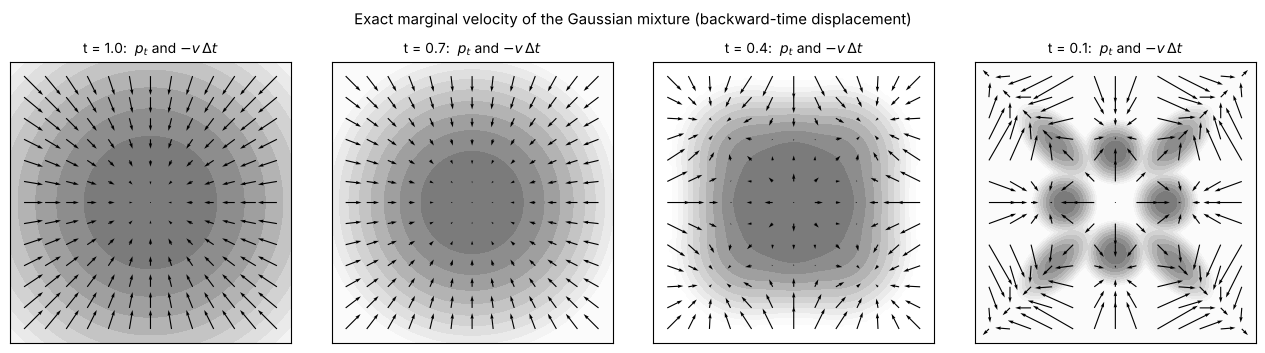

In [6]:
def plot_density(ax, gm, lim=3.0, n=120, cmap="Greys"):
    """Filled contours of log p for a GaussianMixture (background for vector fields)."""
    g1 = torch.linspace(-lim, lim, n)
    X, Y = torch.meshgrid(g1, g1, indexing="xy")
    lp = gm.log_prob(torch.stack([X.flatten(), Y.flatten()], 1)).reshape(n, n)
    levels = np.linspace(lp.max().item() - 10, lp.max().item(), 11)
    # opaque fills (alpha would draw seams between levels); vmax > max keeps the darkest level mid-grey
    ax.contourf(X.numpy(), Y.numpy(), lp.clamp(min=levels[0]).numpy(), levels=levels, cmap=cmap,
                vmin=levels[0], vmax=levels[-1] + 0.6 * (levels[-1] - levels[0]))
    ax.set_aspect("equal")


def plot_field(ax, vfn, t, lim=3.0, n=13, dt=0.15, color="k", width=0.004, **kw):
    """Quiver of the displacement -v * dt (backward-time motion) on a grid."""
    g1 = torch.linspace(-lim * 0.9, lim * 0.9, n)
    X, Y = torch.meshgrid(g1, g1, indexing="xy")
    pts = torch.stack([X.flatten(), Y.flatten()], 1)
    with torch.no_grad():
        d = -dt * vfn(pts.to(device), t).cpu()
    ax.quiver(pts[:, 0], pts[:, 1], d[:, 0], d[:, 1], angles="xy", scale_units="xy", scale=1,
              color=color, width=width, **kw)


def exact_vfn(gm):
    """The exact velocity of a GMM as a function v(x, t) with scalar t."""
    return lambda x, t: exact_velocity(gm, x, t)[0]


fig, axes = plt.subplots(1, 4, figsize=(13, 3.4))
for ax, t in zip(axes, [1.0, 0.7, 0.4, 0.1]):
    plot_density(ax, flow_marginal(gmm, t))
    plot_field(ax, exact_vfn(gmm), t)
    ax.set_title(f"t = {t}:  $p_t$ and $-v\\,\\Delta t$")
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("Exact marginal velocity of the Gaussian mixture (backward-time displacement)", y=1.02)
plt.tight_layout()
plt.show()

At $t=1$ the field is radial: there $\hat x_0 = \mathbb E[x_0]$ for every $x$, so
$v = x - \mathbb E[x_0]$ and every particle first heads to the data mean. As $t$ decreases,
the posterior commits to components, the field splits into basins, and near $t=0$ it points
sharply onto the thin mixture components (round on the inner ring, elongated on the outer one).

## 3 · Training a flow-matching model

The training loop is short enough to write out in full. Per step: draw a batch of pairs
$(x_0,\varepsilon)$, a time $t\sim U(0,1)$ per example, form $x_t$, and regress the network
output onto $\varepsilon - x_0$. Practical details:

* `t[:, None]` broadcasts the per-example time over the data dimensions (for images: `t[:, None, None, None]`);
  forgetting it is the most common shape bug.
* The pair sampler is a function argument, so the *same* loop will later train reflow (fixed
  pairs) and OT-CFM (re-paired batches). An optional label `y` enables classifier-free guidance (Section 8).
* We use the same optimiser, learning rate, warm-up, gradient clipping and **EMA** as
  `dm.train_diffusion` (used since notebook 03; notebook 05 explains the recipe), and sample with the EMA weights.

In [7]:
def make_mlp(n_classes=None):
    """The same small residual MLP for every model in this notebook."""
    return dm.MLPDenoiser(data_dim=2, hidden=128, n_blocks=3, emb_dim=64, n_classes=n_classes).to(device)


def independent_pairs(x_data):
    """Vanilla flow matching: x0 and eps drawn independently."""
    def sample(bs):
        x0 = x_data[torch.randint(0, len(x_data), (bs,), device=x_data.device)]
        return x0, torch.randn_like(x0)
    return sample


def train_flow(model, sample_pairs, steps=STEPS, bs=BATCH, lr=LR, warmup=100, ema_decay=0.999,
               p_uncond=0.0, t_sampler=None, log_every=0):
    """Conditional flow matching. Returns (EMA model, per-step losses)."""
    # weight_decay=0 explicitly: AdamW's default is 0.01, dm.train_diffusion uses 0 (keep the comparison fair)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.0)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min(1.0, (s + 1) / warmup))
    ema, losses = dm.EMA(model, ema_decay), []
    model.train()
    for step in range(steps):
        x0, eps, *y = sample_pairs(bs)                   # optional third element: class labels
        y = y[0] if y else None
        if y is not None and p_uncond > 0:               # CFG: sometimes replace the label by "null"
            y = torch.where(torch.rand(bs, device=y.device) < p_uncond, torch.full_like(y, model.n_classes), y)
        t = torch.rand(bs, device=x0.device) if t_sampler is None else t_sampler(bs, x0.device)
        xt = (1 - t[:, None]) * x0 + t[:, None] * eps    # point on the straight line between the pair
        loss = F.mse_loss(model(xt, time_input(t), y), eps - x0)   # regress onto the pair's velocity
        opt.zero_grad(set_to_none=True)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step(); sched.step(); ema.update(model)
        losses.append(loss.item())
        if log_every and (step + 1) % log_every == 0:
            print(f"  step {step + 1:5d} | loss {np.mean(losses[-log_every:]):.4f}")
    model.eval()
    return ema.model, np.array(losses)


dm.seed_everything(0)
t0 = time.time()
fm_model, fm_losses = train_flow(make_mlp(), independent_pairs(data_dev), log_every=STEPS // 4)
n_params = sum(p.numel() for p in fm_model.parameters())   # (dm.count_params skips the frozen EMA copy)
print(f"flow-matching MLP ({n_params / 1e3:.0f}k params) trained in {time.time() - t0:.0f}s")

  step  1250 | loss 1.5095


  step  2500 | loss 1.4397


  step  3750 | loss 1.4258


  step  5000 | loss 1.4195
flow-matching MLP (126k params) trained in 29s


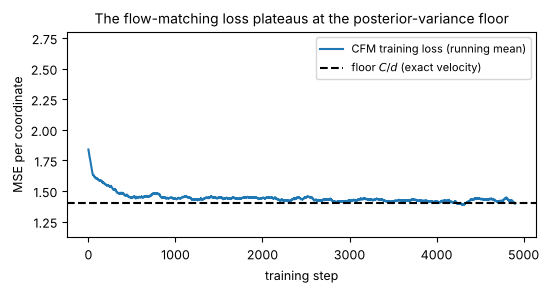

final loss (last 500 steps): 1.425   floor C/d: 1.401


In [8]:
def smooth(x, w=100):
    """Running mean, for readable loss curves."""
    w = min(w, len(x))
    return np.convolve(x, np.ones(w) / w, mode="valid")


fig, ax = plt.subplots(figsize=(5.5, 3))
ax.plot(smooth(fm_losses), color=COL["fm"], label="CFM training loss (running mean)")
# F.mse_loss averages over the 2 coordinates, so compare with C / d
ax.axhline(CFM_FLOOR / 2, color=COL["exact"], ls="--", label="floor $C/d$ (exact velocity)")
ax.set_ylim(CFM_FLOOR / 2 * 0.8, CFM_FLOOR / 2 * 2.0)
ax.set_xlabel("training step"); ax.set_ylabel("MSE per coordinate"); ax.legend()
ax.set_title("The flow-matching loss plateaus at the posterior-variance floor")
plt.tight_layout()
plt.show()
print(f"final loss (last 500 steps): {fm_losses[-500:].mean():.3f}   floor C/d: {CFM_FLOOR / 2:.3f}")

The loss approaches the floor computed from the exact velocity, but never reaches zero:
the remaining gap is, up to minibatch noise, the FM error of the raw (non-EMA) training weights (per
coordinate, i.e. $\mathcal L_{\rm FM}/d$, like the plotted floor $C/d$), which is invisible in the raw loss unless
you know $C$ — a good reason to always keep a toy problem with ground truth around. (The EMA weights we sample with typically do better; the last figure of this
section measures their error directly.)

### Sampling: Euler and Heun from $t=1$ to $t=0$

On a grid $1=t_0>t_1>\dots>t_N=0$ with step $h_i=t_{i+1}-t_i<0$:

* **Euler** (1 network evaluation, NFE, per step): $x_{i+1} = x_i + h_i\,v_\theta(x_i,t_i)$.
* **Heun** (2 NFE per step): predict $\tilde x = x_i + h_i v_\theta(x_i,t_i)$, then correct with the
  average slope, $x_{i+1} = x_i + \tfrac{h_i}{2}\big(v_\theta(x_i,t_i) + v_\theta(\tilde x,t_{i+1})\big)$.
  Second-order accurate: once the steps are small enough for the asymptotic error estimate to apply, it beats
  Euler at equal NFE; with very few steps, spending half the budget on corrections is wasted.

Cost is measured in NFE, so we compare samplers at equal NFE.

In [9]:
@torch.no_grad()
def ode_sample(vfn, x1, n_steps=None, method="euler", ts=None, return_path=False):
    """Integrate dx/dt = vfn(x, t) from t=1 (noise) to t=0 (data).

    Uses a uniform grid with n_steps steps unless an explicit decreasing grid `ts` is given.
    NFE = n_steps for Euler, 2 * n_steps for Heun. return_path=True also returns the states (S+1, N, d).
    """
    ts = torch.linspace(1.0, 0.0, n_steps + 1).tolist() if ts is None else [float(s) for s in ts]
    x, path = x1.clone(), [x1.cpu()]
    for t, s in zip(ts[:-1], ts[1:]):
        h = s - t                                        # negative: we integrate backwards in time
        v = vfn(x, t)
        if method == "euler":
            x = x + h * v
        elif method == "heun":
            x_pred = x + h * v
            x = x + 0.5 * h * (v + vfn(x_pred, s))       # trapezoidal correction
        else:
            raise ValueError(method)
        if return_path:
            path.append(x.cpu())
    return (x, torch.stack(path)) if return_path else x


def model_vfn(model, y=None):
    """Wrap a network as v(x, t) with scalar flow time t in [0, 1]."""
    return lambda x, t: model(x, torch.full((x.shape[0],), time_input(t), device=x.device), y)


def mmd(x):
    """Sample quality vs held-out data. (.cpu(): mmd_rbf works in float64, which MPS lacks.)"""
    return dm.mmd_rbf(x.detach().cpu(), test)

**A fair diffusion baseline.** Same network, same data, same optimiser and number of steps, but
trained with the DDPM $\varepsilon$-prediction loss on the linear VP schedule (notebook 02) via
`dm.train_diffusion`. Its deterministic sampler is DDIM (notebook 04) with `n_steps` = NFE.
(`amp=False` keeps both runs in float32 on any device.) One handicap to keep in mind: `dm.ddim_sample`'s
grid, uniform in the integer step $k$, always spends its last evaluation at $k=0$, where the sample is
already almost clean, so DDIM has effectively one useful step fewer than its NFE. Section 5 removes this
by putting both networks on the same grid.

In [10]:
schedule = dm.NoiseSchedule(1000, "linear", device=device)
dm.seed_everything(0)
t0 = time.time()
ddpm_out = dm.train_diffusion(make_mlp(), data, schedule, steps=STEPS, batch_size=BATCH, lr=LR,
                              ema_decay=0.999, amp=False, progress=False, log_every=STEPS // 4, device=device)
ddpm_model = ddpm_out["ema"].model
print(f"DDPM MLP trained in {time.time() - t0:.0f}s")

step   1250 | loss 0.2683


step   2500 | loss 0.2311


step   3750 | loss 0.2285


step   5000 | loss 0.2282
DDPM MLP trained in 27s


In [11]:
def sw(x):
    """Sliced Wasserstein-1 to held-out data: unbounded, so it still ranks very poor samples."""
    return dm.sliced_wasserstein(x.detach().cpu(), test)


x1_eval = torch.randn(N_EVAL, 2, generator=torch.Generator().manual_seed(4)).to(device)
samplers = {
    "fm_euler": lambda nfe: ode_sample(model_vfn(fm_model), x1_eval, nfe),
    "fm_heun": lambda nfe: ode_sample(model_vfn(fm_model), x1_eval, nfe // 2, "heun") if nfe >= 2 else None,
    "exact_euler": lambda nfe: ode_sample(exact_vfn(gmm), x1_eval, nfe),
    # dm.ddim_sample's grid always ends with an evaluation at step k=0, so it needs >= 2 NFE to move at all
    "ddim": lambda nfe: dm.ddim_sample(ddpm_model, schedule, x1_eval.shape, n_steps=nfe, x_T=x1_eval) if nfe >= 2 else None,
}
quality, quality_sw = {k: [] for k in samplers}, {k: [] for k in samplers}
for nfe in NFES:
    for k, sampler in samplers.items():
        xs = sampler(nfe)
        quality[k].append(mmd(xs) if xs is not None else np.nan)
        quality_sw[k].append(sw(xs) if xs is not None else np.nan)
for title, table in [("MMD^2", quality), ("sliced Wasserstein-1", quality_sw)]:
    print(f"{title} (lower = better)\n{'NFE':>4} | " + " | ".join(f"{k:>11}" for k in table))
    for i, nfe in enumerate(NFES):
        print(f"{nfe:4d} | " + " | ".join(f"{table[k][i]:11.4f}" for k in table))
    print()

MMD^2 (lower = better)
 NFE |    fm_euler |     fm_heun | exact_euler |        ddim
   1 |      4.0072 |         nan |      4.7417 |         nan
   2 |      0.4394 |      0.6826 |      0.4664 |      0.3461
   4 |      0.0494 |      0.0979 |      0.0584 |      0.4861
   8 |      0.0187 |      0.0107 |      0.0208 |      0.0654
  16 |      0.0086 |      0.0065 |      0.0090 |      0.0175
  32 |      0.0063 |      0.0059 |      0.0058 |      0.0090
  64 |      0.0058 |      0.0060 |      0.0050 |      0.0070

sliced Wasserstein-1 (lower = better)
 NFE |    fm_euler |     fm_heun | exact_euler |        ddim
   1 |      0.8642 |         nan |      0.8934 |         nan
   2 |      0.3846 |      0.4722 |      0.3990 |      0.7134
   4 |      0.1380 |      0.1192 |      0.1407 |      0.4604
   8 |      0.0818 |      0.0541 |      0.0823 |      0.1871
  16 |      0.0537 |      0.0463 |      0.0568 |      0.1024
  32 |      0.0448 |      0.0440 |      0.0461 |      0.0829
  64 |      0.0431 |   

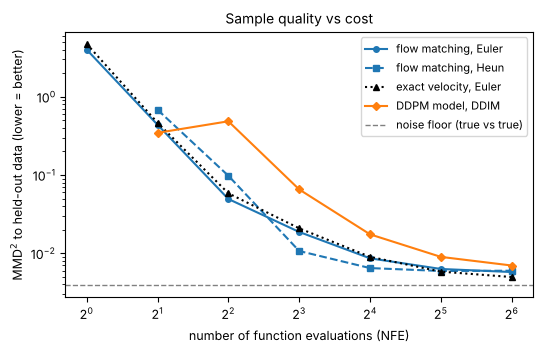

In [12]:
fig, ax = plt.subplots(figsize=(5.5, 3.6))
style = {"fm_euler": ("flow matching, Euler", COL["fm"], "o-"), "fm_heun": ("flow matching, Heun", COL["fm"], "s--"),
         "exact_euler": ("exact velocity, Euler", COL["exact"], "^:"), "ddim": ("DDPM model, DDIM", COL["ddpm"], "D-")}
for k, (lab, c, m) in style.items():
    ax.plot(NFES, quality[k], m, color=c, label=lab, ms=4)
ax.axhline(MMD_FLOOR, color="0.5", lw=1, ls="--", label="noise floor (true vs true)")
ax.set_xscale("log", base=2); ax.set_yscale("log")
ax.set_xlabel("number of function evaluations (NFE)"); ax.set_ylabel("MMD$^2$ to held-out data (lower = better)")
ax.set_title("Sample quality vs cost"); ax.legend()
plt.tight_layout()
plt.show()

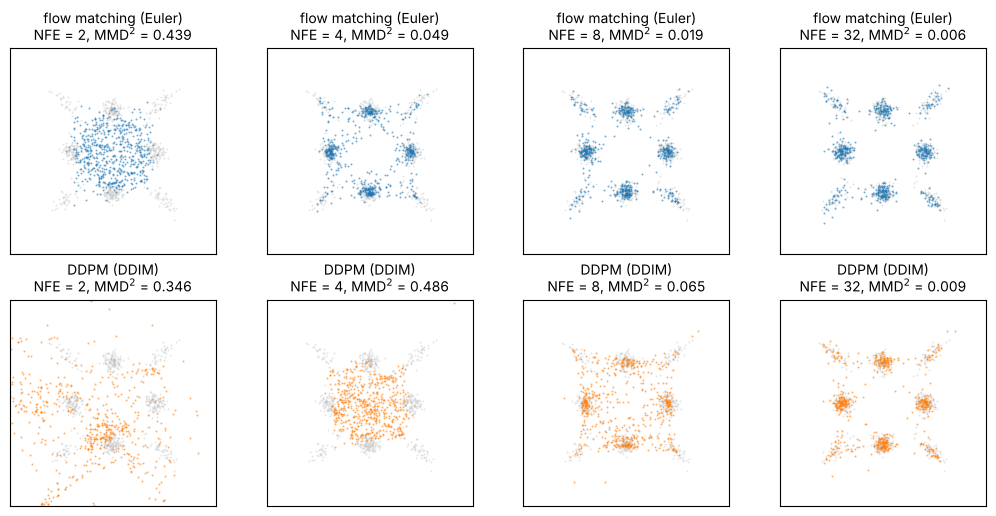

In [13]:
show_nfe = [2, 4, 8, 32]
fig, axes = plt.subplots(2, len(show_nfe), figsize=(2.6 * len(show_nfe), 5.2))
for j, nfe in enumerate(show_nfe):
    for i, (name, xs) in enumerate([
            ("flow matching (Euler)", ode_sample(model_vfn(fm_model), x1_eval, nfe)),
            ("DDPM (DDIM)", dm.ddim_sample(ddpm_model, schedule, x1_eval.shape, n_steps=nfe, x_T=x1_eval))]):
        ax = axes[i, j]
        dm.scatter2d(test[:N_PLOT], ax=ax, c=COL["data"], s=2, alpha=0.4)
        dm.scatter2d(xs[:N_PLOT], ax=ax, c=COL["fm"] if i == 0 else COL["ddpm"], s=2, alpha=0.6,
                     title=f"{name}\nNFE = {nfe}, MMD$^2$ = {mmd(xs):.3f}")
plt.tight_layout()
plt.show()

What to read off these two figures:

* The **exact-velocity** curve isolates pure *discretisation* error (no model error): it falls
  steadily with NFE towards the noise floor and, even at 64 Euler steps, has not quite reached it.
  The learned flow tracks it closely. It falls behind only at the largest budgets (32–64 NFE in the
  MMD table), where the small gap is the model error, while both curves still carry some discretisation error.
  At coarser NFE it is in fact slightly *ahead* of the exact field in this run: model and discretisation
  errors *interact* rather than simply add, and a slightly smoother field can incur less Euler error than
  the exact, sharper one.
* With one Euler step every sampler collapses towards the data mean — the first step uses
  $v(x,1)=x-\mathbb E[x_0]$, so $x_0 = x_1 - v = \mathbb E[x_0]$. Curved paths need several steps.
* Heun is better per *step*, but compare at equal NFE: it typically wins only once the step is small enough for the second-order correction to help (here from about 4–8 NFE on, depending on the metric, until at 32–64 NFE both are limited by the model's own error).
* With 1–2 NFE every sampler here is poor, and MMD cannot rank such samples: an RBF-kernel MMD is
  bounded, so it *saturates* for grossly wrong samples (e.g. DDIM's 2-NFE samples, many far outside the
  plotted window), and differences above roughly 0.1 mean little. The unbounded sliced Wasserstein distance
  in the second table keeps ranking them.
  From a handful of steps on, the flow model beats the DDPM model sampled with DDIM at equal NFE. The gap
  narrows as NFE grows: at 64 NFE the two MMDs are close, although the sliced Wasserstein distance still
  puts DDIM clearly behind. Section 5 shows that this is **not** because flow
  matching is a fundamentally different model; the gap comes from the time grid (including DDIM's
  wasted $k=0$ evaluation) and from the combination of output parametrisation and loss weighting.

Finally, compare the learned and exact velocity fields directly.

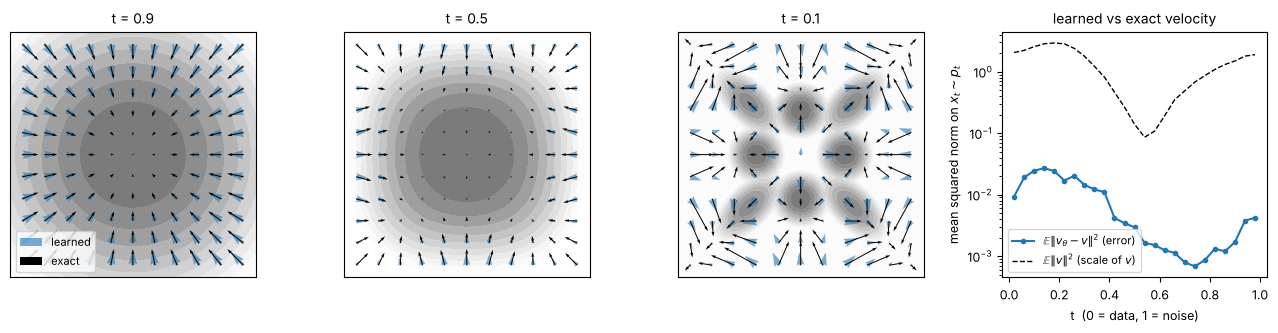

E||v||^2 at t = 0.50: 0.140   (vs 2.95 at its maximum)


In [14]:
def velocity_error_vs_t(vfn, ts, n=N_EVAL, seed=5):
    """Absolute error E||v_model - v_exact||^2 on samples x_t ~ p_t, and the scale E||v_exact||^2, per t."""
    g = torch.Generator().manual_seed(seed)
    errs, scale = [], []
    for t in map(float, ts):
        x0, eps = gmm.sample(n, generator=g), torch.randn(n, 2, generator=g)
        xt = ((1 - t) * x0 + t * eps).to(device)
        v_true, _ = exact_velocity(gmm, xt, t)
        with torch.no_grad():
            v_hat = vfn(xt, t)
        errs.append(sq(v_hat, v_true).mean().item())
        scale.append((v_true ** 2).sum(1).mean().item())
    return np.array(errs), np.array(scale)


ts_err = np.linspace(0.02, 0.98, 9 if FAST else 25)
err_fm, v_scale = velocity_error_vs_t(model_vfn(fm_model), ts_err)

fig, axes = plt.subplots(1, 4, figsize=(13, 3.4))
for ax, t in zip(axes[:3], [0.9, 0.5, 0.1]):
    plot_density(ax, flow_marginal(gmm, t))
    plot_field(ax, model_vfn(fm_model), t, n=11, color=COL["fm"], width=0.012, alpha=0.6, label="learned")
    plot_field(ax, exact_vfn(gmm), t, n=11, color=COL["exact"], width=0.004, label="exact")
    ax.set_title(f"t = {t}"); ax.set_xticks([]); ax.set_yticks([])
axes[0].legend(loc="lower left")
axes[3].semilogy(ts_err, err_fm, "o-", color=COL["fm"], ms=3, label="$\\mathbb{E}\\|v_\\theta - v\\|^2$ (error)")
axes[3].semilogy(ts_err, v_scale, "--", color=COL["exact"], lw=1, label="$\\mathbb{E}\\|v\\|^2$ (scale of $v$)")
axes[3].set_xlabel("t  (0 = data, 1 = noise)"); axes[3].set_ylabel("mean squared norm on $x_t\\sim p_t$")
axes[3].set_title("learned vs exact velocity"); axes[3].legend(loc="lower left")
plt.tight_layout()
plt.show()
i_mid = np.argmin(np.abs(ts_err - 0.5))
print(f"E||v||^2 at t = {ts_err[i_mid]:.2f}: {v_scale[i_mid]:.3f}   (vs {v_scale.max():.2f} at its maximum)")

Learned (thick blue) and exact (thin black) arrows almost coincide wherever $p_t$ has mass; visible
deviations appear only in low-density regions (e.g. the corners at small $t$) that training rarely
visits. The error (right, solid) is small compared with the size of the field at every $t$. It is
largest close to the data (small $t$, roughly 0.1–0.3), where the field is sharp and multi-modal around the thin
components, and smallest at fairly large $t$, where $p_t$ is nearly Gaussian and the field nearly linear in $x$.

The dashed curve has a curious dip near $t=0.5$, where the whole field almost vanishes. Our data are
roughly standardised (mean $\approx0$ and standard deviation $\approx1$ per coordinate, printed at the top; by the
mixture's 90° rotational symmetry the covariance is then $\approx I$). At $t=\tfrac12$, $x_t=\tfrac12(x_0+\varepsilon)$
is symmetric in $x_0$ and $\varepsilon$, so if $x_0$ had the same first two moments as $\varepsilon$, the best *linear*
guesses of $x_0$ and $\varepsilon$ from $x_t$ would coincide and their difference $v$ would be zero; only the
non-Gaussian structure of the data makes $v$ non-zero there. (This is also why a *relative* error,
divided by $\mathbb E\|v\|^2$, would misleadingly peak at $t\approx0.5$.)

## 4 · Trajectories: why the learned flow is curved

Each training pair moves along a straight line, yet the ODE trajectories bend. The reason is
that **many pairs pass through the same point $x$ at the same time $t$, with different velocities**:
the ODE must choose a single velocity there, and it takes their average (the posterior mean). Early on
($t\approx1$) the posterior over $x_0$ is broad, so everybody heads for the data mean; later the
posterior commits and the particle turns towards "its" component.

Two ways to quantify straightness, for a path $x_t$ from $x_1$ to $x_0$:

* **length ratio** $\;\int_0^1\|\dot x_t\|dt\,/\,\|x_1-x_0\|$: 1 for a straight line;
* **Liu et al.'s straightness** $\;S=\int_0^1\mathbb E\,\|\dot x_t - (x_1-x_0)\|^2dt$: the variance of the
  velocity along the path around its time-average. $S=0$ iff every path is a straight line traversed at
  constant speed, which is exactly when a **single Euler step is exact**.

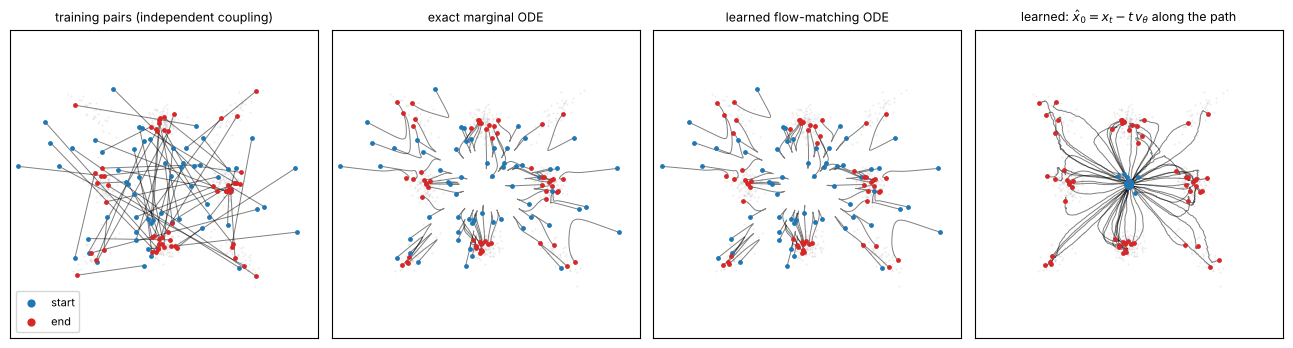

                 paths | length ratio | straightness S
             exact ODE |        1.965 |      1.073
        learned FM ODE |        1.946 |      1.047


In [15]:
def straightness(path):
    """(median length ratio, S) for Euler paths (S+1, N, d) on a uniform grid from t=1 to t=0."""
    steps = path[1:] - path[:-1]
    n = steps.shape[0]
    length = steps.norm(dim=-1).sum(0)
    chord = (path[-1] - path[0]).norm(dim=-1)
    v = -n * steps                                   # Euler velocities (dt = -1/n)
    v_avg = path[0] - path[-1]                       # time-average of v = x_1 - x_0
    S = ((v - v_avg) ** 2).sum(-1).mean()
    return (length / chord).median().item(), S.item()


def posterior_mean_path(path):
    """x0_hat = x_t - t v along an Euler path: the model's running estimate of the final sample."""
    n = path.shape[0] - 1
    v = -n * (path[1:] - path[:-1])
    t = torch.linspace(1, 0, n + 1)[:-1, None, None]
    return path[:-1] - t * v


N_PATH, PATH_STEPS = 60, 100
x1_path = torch.randn(N_PATH, 2, generator=torch.Generator().manual_seed(6)).to(device)
x0_pair = gmm.sample(N_PATH, generator=torch.Generator().manual_seed(7))
cond_paths = torch.stack([x1_path.cpu(), x0_pair])                  # the straight training lines
_, exact_paths = ode_sample(exact_vfn(gmm), x1_path, PATH_STEPS, return_path=True)
_, fm_paths = ode_sample(model_vfn(fm_model), x1_path, PATH_STEPS, return_path=True)

fig, axes = plt.subplots(1, 4, figsize=(13, 3.5))
panels = [("training pairs (independent coupling)", cond_paths),
          ("exact marginal ODE", exact_paths),
          ("learned flow-matching ODE", fm_paths),
          ("learned: $\\hat x_0 = x_t - t\\,v_\\theta$ along the path", posterior_mean_path(fm_paths))]
for ax, (title, p) in zip(axes, panels):
    dm.scatter2d(test[:N_PLOT], ax=ax, c=COL["data"], s=2, alpha=0.3)
    dm.plot_trajectories(p, ax=ax, n_show=N_PATH, lw=0.7, alpha=0.5)
    ax.set_title(title, fontsize=9)
axes[0].legend(loc="lower left", markerscale=2)
plt.tight_layout()
plt.show()

print(f"{'paths':>22} | length ratio | straightness S")
for name, p in [("exact ODE", exact_paths), ("learned FM ODE", fm_paths)]:
    r, S = straightness(p)
    print(f"{name:>22} | {r:12.3f} | {S:10.3f}")

Left: a sample of straight training lines. They intersect all over the picture, although two lines almost
never reach their intersection at the same time. What forces the averaging is that, in the full population
of pairs, a whole continuum of lines (one for every $x_0$) passes through each $(x,t)$. The ODE trajectories
(middle) are solutions of a single smooth velocity field, so two of them can never be at the same place
at the same time (in this 2-D picture they may still cross at different times). They bend: first
inwards, towards the data mean, then out to the components. The learned flow reproduces the exact one
closely. The right panel shows the model's running
guess $\hat x_0$ (blue dots at $t=1$): it starts *at the data mean for every particle* and then
commits — an evidence-accumulation picture familiar from Bayesian observer models. The
straightness numbers ($S>0$, length ratio $>1$) quantify why a single Euler step cannot work here.

## 5 · Flow matching is diffusion in disguise

**Same family of paths.** Every model in this tutorial uses a Gaussian path
$x_t = \alpha_t x_0 + \sigma_t\varepsilon$ (here $\alpha_t$ is the signal coefficient, not DDPM's $1-\beta_t$): VP diffusion has $(\alpha,\sigma)=(\sqrt{\bar\alpha},\sqrt{1-\bar\alpha})$,
flow matching has $(1-t,\,t)$. What matters is the signal-to-noise ratio $\alpha/\sigma$. Divide a VP
state by $\alpha+\sigma$:

$$\frac{x^{\rm VP}}{\alpha+\sigma} = \frac{\alpha}{\alpha+\sigma}x_0 + \frac{\sigma}{\alpha+\sigma}\varepsilon
= x^{\rm FM}_{t}\quad\text{with}\quad t = \frac{\sigma}{\alpha+\sigma}.$$

So a VP state *is* a flow-matching state, up to a known rescaling of $x$ and a change of the time
variable; both carry the same information about $x_0$ and have the same posterior.

**Translating predictions.** Since conditional expectation is linear, $x_t = (1-t)\hat x_0 + t\hat\varepsilon$
holds for the posterior means, and $v = \hat\varepsilon-\hat x_0$. Two linear equations, two unknowns:

$$\boxed{\hat x_0 = x_t - t\,v,\qquad \hat\varepsilon = x_t + (1-t)\,v,\qquad v = \frac{\hat\varepsilon - x_t}{1-t}}$$

**Loss weighting.** If $v_\theta$ has error $\delta$, then $\hat x_0$ has error $-t\delta$ and $\hat\varepsilon$
has error $(1-t)\delta$. Hence, per sample,

$$\|v_\theta - (\varepsilon - x_0)\|^2 = \frac{\|\hat\varepsilon_\theta-\varepsilon\|^2}{(1-t)^2} = \frac{\|\hat x_{0,\theta}-x_0\|^2}{t^2}:$$

flow matching is $\varepsilon$-prediction with weight $1/(1-t)^2$ (or $x_0$-prediction with weight $1/t^2$),
with a different distribution over noise levels than DDPM's uniform integer steps. It is closely
related to the **v-prediction** of Salimans & Ho (2022), which is $\frac{d x_\phi}{d\phi}$ for the
path $\alpha=\cos\phi,\ \sigma=\sin\phi$, just as $\varepsilon-x_0 = \frac{dx_t}{dt}$ for the straight path.

**DDIM is Euler.** A deterministic DDIM step (notebook 04) keeps the predictions
$(\hat x_0,\hat\varepsilon)$ fixed and moves to the next noise level: $x_s = \alpha_s\hat x_0 + \sigma_s\hat\varepsilon$.
In flow coordinates that is $z_s = (1-s)\hat x_0 + s\hat\varepsilon$; and an Euler step from $z_t=(1-t)\hat x_0+t\hat\varepsilon$
gives $z_t + (s-t)(\hat\varepsilon-\hat x_0) = (1-s)\hat x_0 + s\hat\varepsilon$ — **the same point**. The probability-flow
ODE of a diffusion model is a flow, and DDIM is its Euler discretisation in these coordinates.

Notebook 04 (§3.2) showed that DDIM is *also* Euler in the variance-exploding coordinates
$(\tilde x,\tilde\sigma)=(x/\alpha,\ \sigma/\alpha)$. How can one scheme be Euler in two coordinate systems, when Euler is
not coordinate-invariant in general? Because the two systems are related by a map that preserves straight
lines: $z=\tilde x/(1+\tilde\sigma)$, $t=\tilde\sigma/(1+\tilde\sigma)$. DDIM is the exact solution when $(\hat x_0,\hat\varepsilon)$ are frozen
over the step, and in any coordinates where the frozen path is affine in the time variable
($\tilde x=\hat x_0+\tilde\sigma\hat\varepsilon$, or $z=(1-t)\hat x_0+t\hat\varepsilon$) that path is a straight line traversed at constant
speed, which Euler reproduces exactly. In the original VP coordinates the frozen path
$\alpha\hat x_0+\sigma\hat\varepsilon$ is curved, and Euler there is *not* DDIM.

Let's verify all of this numerically, first with the exact mixture.

In [16]:
# CHECK 1: dmtools' VP marginal (notebook 01) equals our flow marginal after x -> x / (alpha + sigma)
for ab in [0.9, 0.5, 0.1]:
    alpha, sigma = math.sqrt(ab), math.sqrt(1 - ab)
    t, c = sigma / (alpha + sigma), alpha + sigma
    lp_vp = gmm.noised(ab).log_prob(xq)
    lp_fm = flow_marginal(gmm, t).log_prob(xq / c) - gmm.d * math.log(c)    # change of variables
    print(f"abar = {ab}: t = {t:.3f}, max |log p_VP - log p_FM| = {(lp_vp - lp_fm).abs().max():.1e}")
    assert torch.allclose(lp_vp, lp_fm, atol=1e-3)

# CHECK 2: x0_hat = x - t v and eps_hat = x + (1-t) v agree with Tweedie's formulas built from the score
for t in [0.2, 0.5, 0.8]:
    v, _ = exact_velocity(gmm, xq, t)
    score = flow_marginal(gmm, t).score(xq)
    x0_tweedie, eps_tweedie = (xq + t ** 2 * score) / (1 - t), -t * score
    e1, e2 = (xq - t * v - x0_tweedie).abs().max().item(), (xq + (1 - t) * v - eps_tweedie).abs().max().item()
    print(f"t = {t}: |x0_hat - Tweedie| = {e1:.1e}, |eps_hat - Tweedie| = {e2:.1e}")
    assert max(e1, e2) < 1e-3

abar = 0.9: t = 0.250, max |log p_VP - log p_FM| = 7.6e-06
abar = 0.5: t = 0.500, max |log p_VP - log p_FM| = 3.8e-06
abar = 0.1: t = 0.750, max |log p_VP - log p_FM| = 1.9e-06
t = 0.2: |x0_hat - Tweedie| = 2.4e-07, |eps_hat - Tweedie| = 9.5e-07
t = 0.5: |x0_hat - Tweedie| = 4.8e-07, |eps_hat - Tweedie| = 9.5e-07
t = 0.8: |x0_hat - Tweedie| = 2.1e-06, |eps_hat - Tweedie| = 4.8e-07


**Converting trained models in both directions.** With the dictionary above we can wrap

* the **flow model as an $\varepsilon$-predictor** in DDPM's discrete VP time $k$ (so that `dm.ddpm_sample` and
  `dm.ddim_sample` can sample it): map $k\mapsto(\alpha_k,\sigma_k)\mapsto t=\sigma_k/(\alpha_k+\sigma_k)$, rescale
  $z = x/(\alpha_k+\sigma_k)$, return $\hat\varepsilon = z + (1-t)v_\theta(z,t)$;
* the **DDPM model as a velocity field** in flow coordinates: map $t\mapsto$ log-SNR $\lambda=2\log\frac{1-t}{t}\mapsto$ a
  (fractional) step $k$ by interpolating the schedule's log-SNR table, rescale $x = z/\sqrt{(1-t)^2+t^2}$, and
  return $v = (\hat\varepsilon-z)/(1-t)$. The DDPM model only knows log-SNRs inside its schedule, so $t$ is clamped to that range.

These wrappers are written for the 2-D MLP (coefficients of shape `(B, 1)`); for images they would need `(B, 1, 1, 1)`.

In [17]:
class FlowAsEps(nn.Module):
    """A flow-matching velocity model exposed as a DDPM eps-model eps(x_vp, k, y) in discrete VP time."""

    def __init__(self, flow_model, schedule):
        super().__init__()
        self.flow, self.schedule = flow_model, schedule
        self.n_classes = flow_model.n_classes            # so dmtools' guidance code can find the null label

    def forward(self, x, k, y=None):
        ab = self.schedule.alpha_bars[k.long()][:, None]
        alpha, sigma = ab.sqrt(), (1 - ab).sqrt()
        t = sigma / (alpha + sigma)                      # same signal-to-noise ratio
        z = x / (alpha + sigma)                          # VP state -> flow state
        v = self.flow(z, time_input(t[:, 0]), y)
        return z + (1 - t) * v                           # eps_hat (identical in both coordinates)


class EpsAsFlow:
    """A DDPM eps-model exposed as a velocity field v(z, t) in flow-matching coordinates."""

    def __init__(self, eps_model, schedule):
        self.model = eps_model
        ab = schedule.alpha_bars.cpu().double().numpy()   # CPU first: MPS has no float64
        lam = np.log(ab) - np.log1p(-ab)                 # log-SNR, decreasing in k
        self.lam_table, self.k_table = lam[::-1].copy(), np.arange(schedule.T, dtype=np.float64)[::-1].copy()
        t_of = lambda a: math.sqrt(1 - a) / (math.sqrt(a) + math.sqrt(1 - a))
        self.t_min, self.t_max = t_of(ab[0]), t_of(ab[-1])   # the SNR range the model was trained on

    def __call__(self, z, t):
        t = min(max(t, self.t_min), self.t_max)
        k = float(np.interp(2 * math.log((1 - t) / t), self.lam_table, self.k_table))   # fractional step
        x = z / math.sqrt((1 - t) ** 2 + t ** 2)         # flow state -> VP state
        eps = self.model(x, torch.full((z.shape[0],), k, device=z.device))
        return (eps - z) / (1 - t)


def ddim_grid_in_flow_time(n_steps):
    """dm.ddim_sample's integer steps k (uniform in k, notebook 04) and the matching flow times t."""
    ks = np.unique(np.linspace(0, schedule.T - 1, n_steps).round().astype(int))[::-1]
    ab = schedule.alpha_bars.cpu().double().numpy()[ks]   # CPU first: MPS has no float64
    return ks, np.sqrt(1 - ab) / (np.sqrt(ab) + np.sqrt(1 - ab))


# CHECK 3: Euler on the converted DDPM model, on the image of DDIM's own time grid, reproduces dm.ddim_sample
n_ddim = 10
ks, t_ks = ddim_grid_in_flow_time(n_ddim)
xT = torch.randn(N_EVAL, 2, generator=torch.Generator().manual_seed(8)).to(device)
with torch.no_grad():
    x_ddim = dm.ddim_sample(ddpm_model, schedule, xT.shape, n_steps=n_ddim, x_T=xT)
    ab_T = schedule.alpha_bars[ks[0]].item()
    z_T = xT / (math.sqrt(ab_T) + math.sqrt(1 - ab_T))                     # same starting point, flow coords
    x_euler = ode_sample(EpsAsFlow(ddpm_model, schedule), z_T, ts=list(t_ks) + [0.0])
diff = (x_ddim - x_euler).abs().max().item()
print(f"DDIM ({n_ddim} steps) vs Euler on the converted model: max |difference| = {diff:.1e}")
assert diff < 1e-3

DDIM (10 steps) vs Euler on the converted model: max |difference| = 5.4e-05


DDIM and Euler-in-flow-coordinates produce the same samples to float precision. Now the other
direction: sample the **flow-matching model with the DDPM machinery** of notebooks 02 and 04,
including the *stochastic* ancestral sampler — a flow model can be sampled stochastically too.

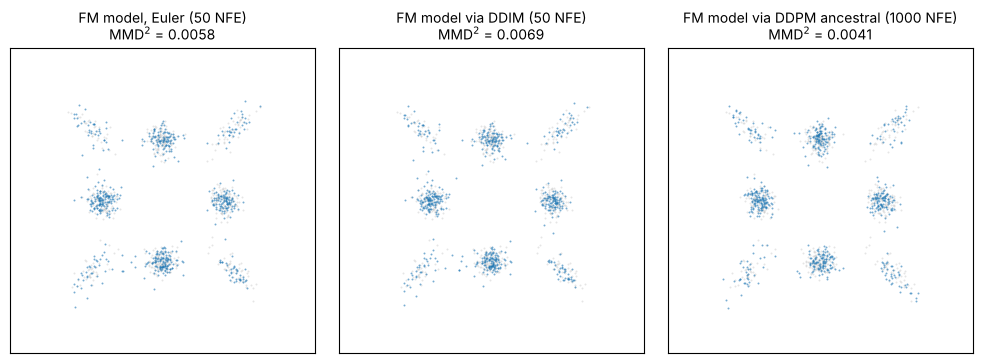

In [18]:
fm_as_eps = FlowAsEps(fm_model, schedule)
with torch.no_grad():
    samples = {"FM model, Euler (50 NFE)": ode_sample(model_vfn(fm_model), x1_eval, 50),
               "FM model via DDIM (50 NFE)": dm.ddim_sample(fm_as_eps, schedule, x1_eval.shape, n_steps=50, x_T=x1_eval),
               "FM model via DDPM ancestral (1000 NFE)": dm.ddpm_sample(fm_as_eps, schedule, x1_eval.shape)}
fig, axes = plt.subplots(1, 3, figsize=(10, 3.5))
for ax, (name, xs) in zip(axes, samples.items()):
    dm.scatter2d(test[:N_PLOT], ax=ax, c=COL["data"], s=2, alpha=0.4)
    dm.scatter2d(xs[:N_PLOT], ax=ax, c=COL["fm"], s=2, alpha=0.6, title=f"{name}\nMMD$^2$ = {mmd(xs):.4f}")
plt.tight_layout()
plt.show()

All three samplers give good samples from the same flow-matching network: the
"diffusion vs flow" distinction is about *how a model is trained and parametrised*, not about
which sampler you may use. (The stochastic sampler costs 20× more evaluations, but its injected
noise can also correct some accumulated error — in this run it has the lowest MMD of the three, close to
the noise floor. This is the usual stochastic-vs-deterministic trade-off.)

**So where did the few-step gap of Section 3 come from?** Three suspects: (i) the *time grid* —
DDIM's grid is uniform in the integer step $k$, which for the linear schedule packs most steps at
high noise and wastes the last one at $k=0$; (ii) the *output parametrisation* ($\varepsilon$ vs $v$); and
(iii) the *training objective*: how the loss weights errors at each noise level, and how often each
noise level is sampled. (ii) and (iii) are entangled, because for a $v$-head
$\|v_\theta-u\|^2=\|\hat\varepsilon_\theta-\varepsilon\|^2/(1-t)^2$, as shown above: "predict $v$" and "weight the
$\varepsilon$-error by $1/(1-t)^2$" describe the same objective; only the network's output layer differs.
The experiment below isolates the **grid only**: it samples the converted DDPM model with exactly the
flow model's Euler sampler on a uniform-in-$t$ grid, and compares the velocity errors of both networks
as a function of $t$. (Exercise 6 pulls (ii) and (iii) apart.)

8-step DDIM grid expressed in flow time t: [0.994 0.976 0.93  0.838 0.702 0.535 0.331 0.01 ] -> 0
8-step uniform flow grid:                  [1.    0.875 0.75  0.625 0.5   0.375 0.25  0.125] -> 0


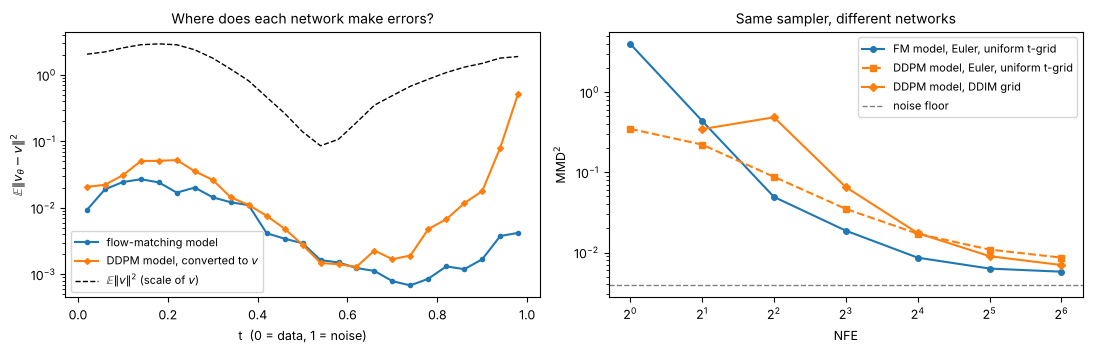

In [19]:
eps_as_flow = EpsAsFlow(ddpm_model, schedule)
err_ddpm, _ = velocity_error_vs_t(eps_as_flow, ts_err)
quality["ddpm_euler"] = [mmd(ode_sample(eps_as_flow, x1_eval, nfe)) for nfe in NFES]

print("8-step DDIM grid expressed in flow time t:", np.round(ddim_grid_in_flow_time(8)[1], 3), "-> 0")
print("8-step uniform flow grid:                 ", np.round(np.linspace(1, 0, 9)[:-1], 3), "-> 0")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].semilogy(ts_err, err_fm, "o-", color=COL["fm"], ms=3, label="flow-matching model")
axes[0].semilogy(ts_err, err_ddpm, "D-", color=COL["ddpm"], ms=3, label="DDPM model, converted to $v$")
axes[0].semilogy(ts_err, v_scale, "--", color=COL["exact"], lw=1, label="$\\mathbb{E}\\|v\\|^2$ (scale of $v$)")
axes[0].set_xlabel("t  (0 = data, 1 = noise)"); axes[0].set_ylabel("$\\mathbb{E}\\|v_\\theta - v\\|^2$")
axes[0].set_title("Where does each network make errors?"); axes[0].legend()
for k, lab, c, m in [("fm_euler", "FM model, Euler, uniform t-grid", COL["fm"], "o-"),
                     ("ddpm_euler", "DDPM model, Euler, uniform t-grid", COL["ddpm"], "s--"),
                     ("ddim", "DDPM model, DDIM grid", COL["ddpm"], "D-")]:
    axes[1].plot(NFES, quality[k], m, color=c, ms=4, label=lab)
axes[1].axhline(MMD_FLOOR, color="0.5", lw=1, ls="--", label="noise floor")
axes[1].set_xscale("log", base=2); axes[1].set_yscale("log")
axes[1].set_xlabel("NFE"); axes[1].set_ylabel("MMD$^2$"); axes[1].set_title("Same sampler, different networks")
axes[1].legend()
plt.tight_layout()
plt.show()

Left: converted to velocities, the $\varepsilon$-model's errors are amplified by $1/(1-t)$ near pure
noise ($v=(\hat\varepsilon - x_t)/(1-t)$): a small error in $\hat\varepsilon$ becomes a large error in the
direction of motion, exactly where a few-step sampler takes its first and largest step. This is also
where the DDPM objective cares least about $\varepsilon$-errors compared with flow matching (weighting plot
below), so the head and the weighting conspire. The flow model, trained on $v$, has no such blow-up.

Right: grid and network interact. DDIM's grid (printed above) is uniform in the integer step
$k$, which for the linear schedule means many small steps near $t=1$ — exactly where the $\varepsilon$-model's
velocity is unreliable — followed by one or two huge steps across the low-noise region and a wasted
evaluation at $k=0$. With very few steps that wastes evaluations, and the uniform grid serves the DDPM
network better; with more steps the small high-noise steps of DDIM's grid pay off for it. Even on the
same uniform grid, though, the DDPM network stays behind the flow network over most budgets: that
residual gap belongs to suspects (ii)+(iii), the head and the training objective, which this experiment
cannot separate. (At 1–2 NFE every method is poor, so ignore the ranking there.)
The lesson generalises (compare notebook 04 §6 on where to put the steps): **put small steps where the
network's velocity is least reliable**, and prefer a parametrisation and weighting that make the network
reliable where your sampler takes big steps.

**Loss weighting across noise levels.** Writing every objective as a weighted
$\varepsilon$-MSE per unit of log-SNR $\lambda$ makes them comparable (Kingma & Gao 2023). For flow matching with
$t\sim U(0,1)$: $\lambda = 2\log\frac{1-t}{t}$, $|dt/d\lambda| = t(1-t)/2$, and weight $1/(1-t)^2$, so the
effective weight is $\frac{t}{2(1-t)} = \tfrac12 e^{-\lambda/2}$. For DDPM's simple loss it is just the density of
$\lambda$ under uniform integer steps. SD3 samples $t$ from a **logit-normal**, $t=\mathrm{sigmoid}(n)$, $n\sim\mathcal N(0,1)$;
since $\mathrm{logit}\,t=-\lambda/2$, its density per unit $\lambda$ is $\tfrac12\mathcal N(\lambda/2;0,1)$, times the same $1/(1-t)^2$.

One thing weighting does **not** change is the answer. For any time density $p(t)$ and weight $w(t)>0$,
the argument of Section 1 applies at each $t$ separately, so the population minimiser is still the
posterior mean $v(x,t)$ wherever $p(t)w(t)>0$. The weighting only matters for a finite network trained for
finite time: it decides at which noise levels the inevitable errors end up smallest, and how noisy the
gradients are.

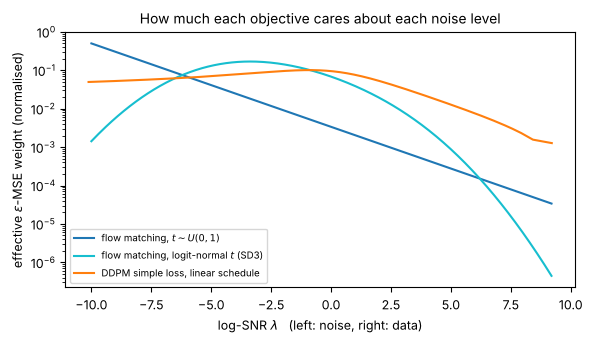

logit-normal: density of t peaks at t = 0.5 (lambda = 0); effective eps-weight peaks at lambda = -3.38, i.e. t = 0.84


In [20]:
lam = np.linspace(-10, 10, 400)
t_of_lam = 1 / (1 + np.exp(lam / 2))                       # inverse of lambda = 2 log((1-t)/t)
w_fm = 0.5 * np.exp(-lam / 2)                               # uniform t, eps-weight 1/(1-t)^2
w_lognorm = np.exp(-(lam / 2) ** 2 / 2) / math.sqrt(2 * math.pi) / 2 / (1 - t_of_lam) ** 2
lam_ddpm = schedule.log_snr.cpu().numpy()                   # one value per integer step, decreasing
dens_ddpm = 1.0 / (len(lam_ddpm) * np.abs(np.gradient(lam_ddpm)))   # density of lambda under uniform k

fig, ax = plt.subplots(figsize=(6, 3.5))
for x_l, w, lab, c in [(lam, w_fm, "flow matching, $t\\sim U(0,1)$", COL["fm"]),
                       (lam, w_lognorm, "flow matching, logit-normal $t$ (SD3)", "tab:cyan"),
                       (lam_ddpm, dens_ddpm, "DDPM simple loss, linear schedule", COL["ddpm"])]:
    m = (x_l >= lam_ddpm.min()) & (x_l <= lam_ddpm.max())   # normalise over the range DDPM covers
    area = abs(np.sum(0.5 * (w[m][1:] + w[m][:-1]) * np.diff(x_l[m])))   # trapezoid rule
    ax.semilogy(x_l[m], w[m] / area, color=c, label=lab)
ax.set_xlabel("log-SNR $\\lambda$   (left: noise, right: data)")
ax.set_ylabel("effective $\\varepsilon$-MSE weight (normalised)")
ax.set_title("How much each objective cares about each noise level"); ax.legend(fontsize=7, loc="lower left")
plt.tight_layout()
plt.show()
i_pk = np.argmax(w_lognorm)
print(f"logit-normal: density of t peaks at t = 0.5 (lambda = 0); effective eps-weight peaks at "
      f"lambda = {lam[i_pk]:.2f}, i.e. t = {t_of_lam[i_pk]:.2f}")

Uniform-$t$ flow matching puts exponentially more weight on noisy inputs (low $\lambda$) than DDPM's
simple loss. SD3's logit-normal sampling has a density in $t$ that peaks at $t=0.5$ ($\lambda=0$), but the
$1/(1-t)^2$ $\varepsilon$-weight moves its *effective* weight peak well into the noisy side (setting the
derivative of $\log[e^{-\lambda^2/8}(1+e^{-\lambda/2})^2]$ to zero gives $\lambda^\ast=-4t^\ast$, i.e. $\lambda^\ast\approx-3.4$,
$t^\ast\approx0.84$, as printed). Relative to uniform-$t$ flow matching it strongly suppresses both
extremes; Esser et al. found this best for image quality.
Taken together: flow matching = a Gaussian diffusion with a particular time parametrisation, output
parametrisation ($v$), and loss weighting — which is exactly why it slots into existing diffusion
tooling (samplers, guidance, distillation) so easily.

## 6 · Rectified flow: straightening by "reflow"

The curvature comes from the *coupling* between noise and data: pairing them independently sends
many lines through every $(x,t)$. Liu, Gong & Liu (2023) observe that the trained ODE itself defines a much better
coupling: draw $\varepsilon$, integrate to get $\hat x_0=\mathrm{ODE}_{1\to0}(\varepsilon)$, and **retrain on the pairs
$(\hat x_0,\varepsilon)$**. The new coupling is deterministic, and it has the same marginals when the ODE is
exact (with a learned model, $\hat x_0$ follows the *model's* distribution instead). They prove that this
"rectification" does not increase any convex transport cost, and that the straightness summed over
repeated reflows is bounded, so iterating reflow drives $S$ towards zero (at rate $O(1/K)$ for the best of
$K$ iterates; not necessarily monotonically). Practicalities: generating pairs costs one accurate ODE solve
per pair; any error of the first model is baked into the pairs (so the sample-quality floor can only get
worse); and one usually fine-tunes from the first model rather than starting from scratch.

In [21]:
N_PAIRS = 2_000 if FAST else 20_000
REFLOW_STEPS = 150 if FAST else STEPS // 2

eps_pairs = torch.randn(N_PAIRS, 2, generator=torch.Generator().manual_seed(9)).to(device)
t0 = time.time()
x0_pairs = ode_sample(model_vfn(fm_model), eps_pairs, 25, method="heun")      # 50 NFE: accurate solve
print(f"generated {N_PAIRS} (noise, sample) pairs in {time.time() - t0:.0f}s")


def coupled_pairs(x0, eps):
    """Reflow: sample from a fixed, deterministic coupling (x0_i, eps_i)."""
    def sample(bs):
        idx = torch.randint(0, len(x0), (bs,), device=x0.device)
        return x0[idx], eps[idx]
    return sample


rf_model = copy.deepcopy(fm_model)                   # fine-tune the 1-rectified flow ...
for p in rf_model.parameters():                      # (EMA copies are frozen; unfreeze)
    p.requires_grad_(True)
dm.seed_everything(1)
t0 = time.time()
rf_model, rf_losses = train_flow(rf_model, coupled_pairs(x0_pairs, eps_pairs), steps=REFLOW_STEPS,
                                 lr=LR / 2, log_every=REFLOW_STEPS // 3)
print(f"reflow trained in {time.time() - t0:.0f}s; final loss {rf_losses[-200:].mean():.4f} "
      f"(vs {fm_losses[-200:].mean():.4f} for the first model)")

generated 20000 (noise, sample) pairs in 3s


  step   833 | loss 0.0263


  step  1666 | loss 0.0013


  step  2499 | loss 0.0006
reflow trained in 13s; final loss 0.0004 (vs 1.4228 for the first model)


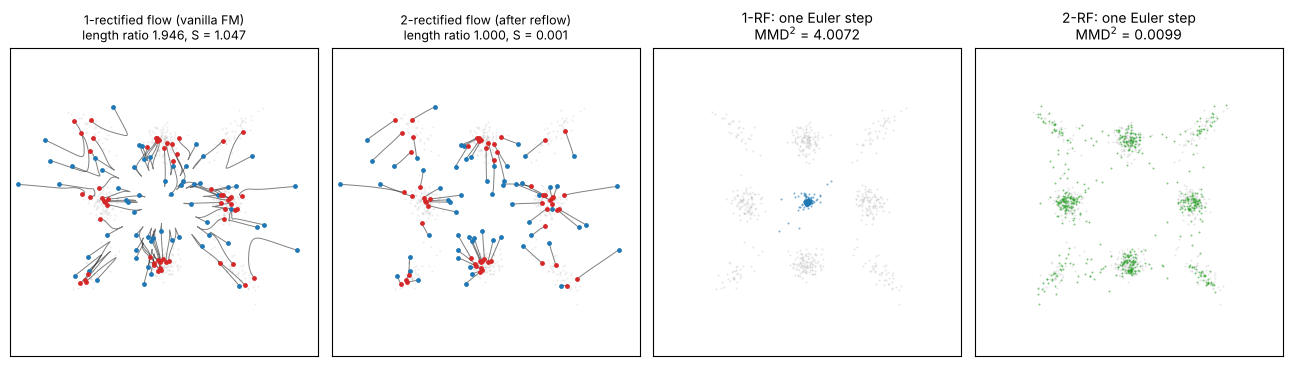

In [22]:
_, rf_paths = ode_sample(model_vfn(rf_model), x1_path, PATH_STEPS, return_path=True)
fig, axes = plt.subplots(1, 4, figsize=(13, 3.5))
for ax, (title, p) in zip(axes[:2], [("1-rectified flow (vanilla FM)", fm_paths), ("2-rectified flow (after reflow)", rf_paths)]):
    dm.scatter2d(test[:N_PLOT], ax=ax, c=COL["data"], s=2, alpha=0.3)
    dm.plot_trajectories(p, ax=ax, n_show=N_PATH, lw=0.7, alpha=0.5)
    r, S = straightness(p)
    ax.set_title(f"{title}\nlength ratio {r:.3f}, S = {S:.3f}", fontsize=9)
for ax, (name, model, c) in zip(axes[2:], [("1-RF", fm_model, COL["fm"]), ("2-RF", rf_model, COL["reflow"])]):
    xs = ode_sample(model_vfn(model), x1_eval, 1)
    dm.scatter2d(test[:N_PLOT], ax=ax, c=COL["data"], s=2, alpha=0.4)
    dm.scatter2d(xs[:N_PLOT], ax=ax, c=c, s=2, alpha=0.6, title=f"{name}: one Euler step\nMMD$^2$ = {mmd(xs):.4f}")
plt.tight_layout()
plt.show()

After one reflow the trajectories are nearly straight lines, so a single Euler step lands almost
where the full ODE would: one network evaluation now produces a sensible sample, instead of
collapsing onto the data mean. The reflow training loss also drops far below the first model's
floor $C$: the new coupling is deterministic, and its straight lines join the two ends of ODE paths that
never meet at the same time, so they rarely pass through the same $(x,t)$ and there is little posterior
variance left in $\varepsilon - x_0$ given $x_t$.

## 7 · Mini-batch optimal-transport couplings

Reflow fixes the coupling *after* training. Tong et al. (2023) (and Pooladian et al. 2023) choose a better
coupling *during* training: within each batch, re-pair noise and data to minimise the total squared
distance $\sum_i\|x_0^{(i)}-\varepsilon^{(\pi(i))}\|^2$ over permutations $\pi$ — a linear assignment problem
solved exactly in $O(B^3)$ time by the Hungarian algorithm or, as in `scipy.optimize.linear_sum_assignment`,
by a Jonker–Volgenant variant (cheap for $B\lesssim 10^3$).

* **Marginals are preserved**: the batch's noise vectors are only permuted, so a randomly chosen pair still has
  $x_0\sim p_{\rm data}$ and $\varepsilon\sim\mathcal N(0,I)$ — the theory of Section 1 holds for *any* coupling with these marginals.
* **Why straighter**: for the exact quadratic-cost OT plan $x_0=T(\varepsilon)$, two interpolants never meet at the
  *same time*: cyclical monotonicity makes $\varepsilon\mapsto(1-t)T(\varepsilon)+t\varepsilon$ injective for each fixed $t$ (the segments
  may still intersect in space at different times). So only one pair passes through each $(x,t)$, the posterior
  over pairs is a point mass, the marginal velocity equals the per-pair velocity, and the ODE paths are the straight
  segments themselves. A mini-batch only approximates the OT plan, and less well in high dimension, where a batch
  covers the space sparsely.

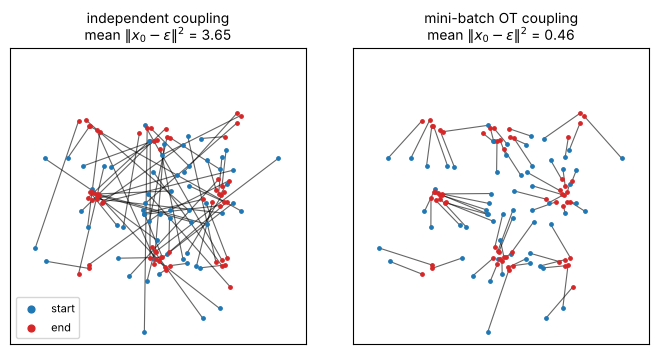

In [23]:
def ot_pairs(x_data):
    """Mini-batch OT-CFM: re-pair noise and data within each batch by optimal assignment."""
    def sample(bs):
        x0 = x_data[torch.randint(0, len(x_data), (bs,), device=x_data.device)]
        eps = torch.randn_like(x0)
        cost = torch.cdist(x0, eps).pow(2).cpu().numpy()
        _, col = linear_sum_assignment(cost)             # rows come back as 0..bs-1
        return x0, eps[torch.as_tensor(col, device=x0.device)]
    return sample


# visualise one small batch under both couplings
torch.manual_seed(10)
fig, axes = plt.subplots(1, 2, figsize=(7, 3.5))
for ax, (name, sampler) in zip(axes, [("independent coupling", independent_pairs(data_dev)),
                                      ("mini-batch OT coupling", ot_pairs(data_dev))]):
    torch.manual_seed(10)                                # same batch for both panels
    x0_b, eps_b = sampler(64)
    dm.plot_trajectories(torch.stack([eps_b.cpu(), x0_b.cpu()]), ax=ax, n_show=64, lw=0.8, alpha=0.6)
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"{name}\nmean $\\|x_0-\\varepsilon\\|^2$ = {sq(x0_b, eps_b).mean():.2f}")
axes[0].legend(loc="lower left", markerscale=2)
plt.tight_layout()
plt.show()

Same 64 noise vectors and data points; only the pairing differs. The OT pairing removes most crossings and
shortens the average displacement. Train exactly as before, only with the new pair sampler:

In [24]:
dm.seed_everything(0)
t0 = time.time()
ot_model, ot_losses = train_flow(make_mlp(), ot_pairs(data_dev), log_every=STEPS // 4)
print(f"OT-CFM trained in {time.time() - t0:.0f}s; final loss {ot_losses[-200:].mean():.4f}")

  step  1250 | loss 0.0642


  step  2500 | loss 0.0395


  step  3750 | loss 0.0376


  step  5000 | loss 0.0358
OT-CFM trained in 60s; final loss 0.0357


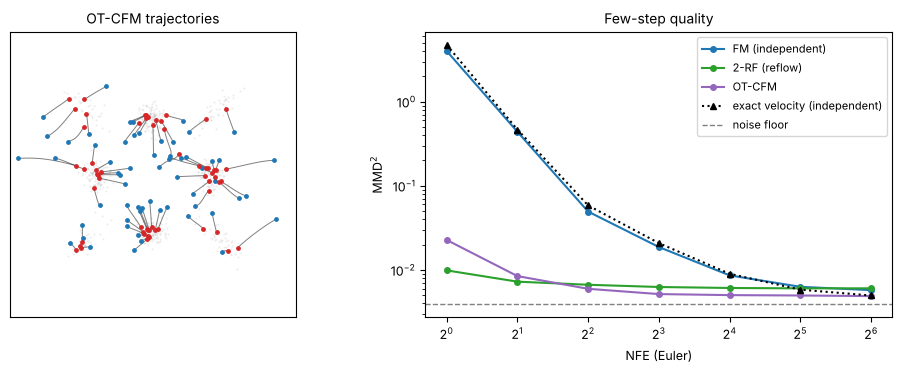

             model | length ratio | straightness S | MMD@1 | MMD@2 | MMD@4 | MMD@8 | MMD@16 | MMD@32 | MMD@64
  FM (independent) |        1.946 |          1.047 | 4.0072 | 0.4394 | 0.0494 | 0.0187 | 0.0086 | 0.0063 | 0.0058
     2-RF (reflow) |        1.000 |          0.001 | 0.0099 | 0.0073 | 0.0067 | 0.0063 | 0.0061 | 0.0060 | 0.0061
            OT-CFM |        1.001 |          0.005 | 0.0227 | 0.0085 | 0.0060 | 0.0052 | 0.0050 | 0.0050 | 0.0049


In [25]:
_, ot_paths = ode_sample(model_vfn(ot_model), x1_path, PATH_STEPS, return_path=True)
models = {"FM (independent)": (fm_model, COL["fm"], fm_paths),
          "2-RF (reflow)": (rf_model, COL["reflow"], rf_paths),
          "OT-CFM": (ot_model, COL["ot"], ot_paths)}
few_nfe = {name: [mmd(ode_sample(model_vfn(m), x1_eval, nfe)) for nfe in NFES] for name, (m, _, _) in models.items()}

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
dm.scatter2d(test[:N_PLOT], ax=axes[0], c=COL["data"], s=2, alpha=0.3)
dm.plot_trajectories(ot_paths, ax=axes[0], n_show=N_PATH, lw=0.7, alpha=0.5)
axes[0].set_title("OT-CFM trajectories")
for name, (_, c, _) in models.items():
    axes[1].plot(NFES, few_nfe[name], "o-", color=c, ms=4, label=name)
axes[1].plot(NFES, quality["exact_euler"], "^:", color=COL["exact"], ms=4, label="exact velocity (independent)")
axes[1].axhline(MMD_FLOOR, color="0.5", lw=1, ls="--", label="noise floor")
axes[1].set_xscale("log", base=2); axes[1].set_yscale("log")
axes[1].set_xlabel("NFE (Euler)"); axes[1].set_ylabel("MMD$^2$"); axes[1].set_title("Few-step quality")
axes[1].legend()
plt.tight_layout()
plt.show()

print(f"{'model':>18} | length ratio | straightness S | " + " | ".join(f"MMD@{n}" for n in NFES))
for name, (_, _, p) in models.items():
    r, S = straightness(p)
    print(f"{name:>18} | {r:12.3f} | {S:14.3f} | " + " | ".join(f"{q:6.4f}" for q in few_nfe[name]))

Both remedies straighten the flow and make 1–2-step Euler sampling usable. Note the shape of the
reflow curve: once the paths are straight, extra steps buy almost nothing, and its many-step quality is
capped by the first model, whose samples it was trained on. OT-CFM, trained on the real data, has no such
cap: in this run it has the lowest MMD of all three models from about 4 NFE on. The two remedies come at very
different costs: reflow needs a trained model, an ODE solve per training pair and a second training run, and
inherits the first model's errors; OT-CFM costs one assignment per batch and nothing else — but its benefit shrinks
as the dimension grows relative to the batch size, which is why large image models do not rely on it
alone (and why few-step distillation methods such as consistency models or adversarial diffusion
distillation exist). In 2-D, batches of 256 already give a good approximation of the OT plan. (With a network
this tiny, scipy's CPU assignment is still a sizeable part of each training step, which is why OT-CFM trained
more slowly than the first model here: compare the printed times. For a large network it is negligible.)

## 8 · Flow matching in practice

**Where it is used.** Stable Diffusion 3 (Esser et al. 2024) and Flux are rectified-flow transformers in the
latent space of an autoencoder (notebook 09); flow matching is also used in video (e.g. Meta's Movie Gen,
Polyak et al. 2024), speech (Voicebox, Le et al. 2023) and robot policies (e.g. $\pi_0$, Black et al. 2024; see
notebook 10). The recipe is this notebook's, with a bigger network.

**The knobs that matter.**
* *Timestep distribution.* Uniform $t$ is a choice, not a law. SD3 found logit-normal sampling of $t$ (centred
  at $t=0.5$) best, i.e. less training signal at the two extremes (see the weighting plot in Section 5;
  the minimiser is the same, only the allocation of the network's errors changes). For
  higher resolutions they also *shift* $t$ towards noise, $t\mapsto \frac{s\,t}{1+(s-1)t}$ with $s>1$, because
  more pixels make the same $t$ effectively less noisy.
* *Sampler and steps.* Plain Euler with roughly 20–50 uniform or shifted steps is the default for large
  flow models; Heun / higher-order solvers help at moderate budgets (from about 4–8 NFE on in Section 3), but not
  with only a handful of steps. For 1–4 steps you need a straightened or distilled model (e.g. InstaFlow,
  a reflowed and distilled Stable Diffusion, or Flux "schnell").
* *Parametrisation.* Predicting $v$ is well conditioned at both ends of the path (Section 5, Exercise 6), one reason the
  community moved away from pure $\varepsilon$-prediction for few-step sampling.
* *Guidance.* Classifier-free guidance (notebook 06) carries over verbatim:
  $v_w = v_\theta(x,t,\varnothing) + w\,\big(v_\theta(x,t,y) - v_\theta(x,t,\varnothing)\big)$. Because $v = (\hat\varepsilon - x)/(1-t)$
  is an affine function of $\hat\varepsilon$ with an $x$-term that does not depend on the label, guiding $v$ is
  *identical* to guiding $\hat\varepsilon$ (or $\hat x_0$, or the score) with the same $w$.

Let's train a class-conditional flow model on `dm.labelled_gmm()` (three classes; class 1 sits in
the middle, between the other two, and overlaps class 2), with label dropout, and check the guidance identity against dmtools'
own $\varepsilon$-space CFG implementation via the `FlowAsEps` wrapper.

In [26]:
lgmm, comp_class = dm.labelled_gmm()
x_lab, k_lab = lgmm.sample(N_TRAIN, return_labels=True, generator=torch.Generator().manual_seed(11))
y_lab = torch.as_tensor(comp_class)[k_lab]
x_lab, y_lab = x_lab.to(device), y_lab.to(device)


def labelled_pairs(x, y):
    """Independent coupling plus each data point's class label."""
    def sample(bs):
        idx = torch.randint(0, len(x), (bs,), device=x.device)
        return x[idx], torch.randn_like(x[idx]), y[idx]
    return sample


dm.seed_everything(0)
t0 = time.time()
cond_model, _ = train_flow(make_mlp(n_classes=3), labelled_pairs(x_lab, y_lab), p_uncond=0.2,
                           steps=STEPS if FAST else STEPS * 2 // 3)
print(f"conditional flow model trained in {time.time() - t0:.0f}s")


def guided_vfn(model, label, w):
    """CFG on velocities: v_uncond + w (v_cond - v_uncond)."""
    def vfn(x, t):
        tt = torch.full((x.shape[0],), time_input(t), device=x.device)
        y = torch.full((x.shape[0],), label, device=x.device, dtype=torch.long)
        v_c, v_u = model(x, tt, y), model(x, tt, torch.full_like(y, model.n_classes))
        return v_u + w * (v_c - v_u)
    return vfn


# CHECK: guided velocity -> eps equals dmtools' CFG computed in eps-space on the wrapped model
k_chk, w_chk = 400, 3.0
ab = schedule.alpha_bars[k_chk].item()
alpha, sigma = math.sqrt(ab), math.sqrt(1 - ab)
t_chk = sigma / (alpha + sigma)
x_vp = torch.randn(256, 2, device=device)
with torch.no_grad():
    eps_dm, _ = dm.model_predictions(FlowAsEps(cond_model, schedule), x_vp, k_chk, schedule,
                                     y=torch.full((256,), 1, device=device, dtype=torch.long), guidance_scale=w_chk)
    z = x_vp / (alpha + sigma)
    eps_from_v = z + (1 - t_chk) * guided_vfn(cond_model, 1, w_chk)(z, t_chk)
gdiff = (eps_dm - eps_from_v).abs().max().item()
print(f"guiding v vs guiding eps (dmtools): max |difference| = {gdiff:.1e}")
assert gdiff < 1e-3

conditional flow model trained in 19s
guiding v vs guiding eps (dmtools): max |difference| = 2.6e-06


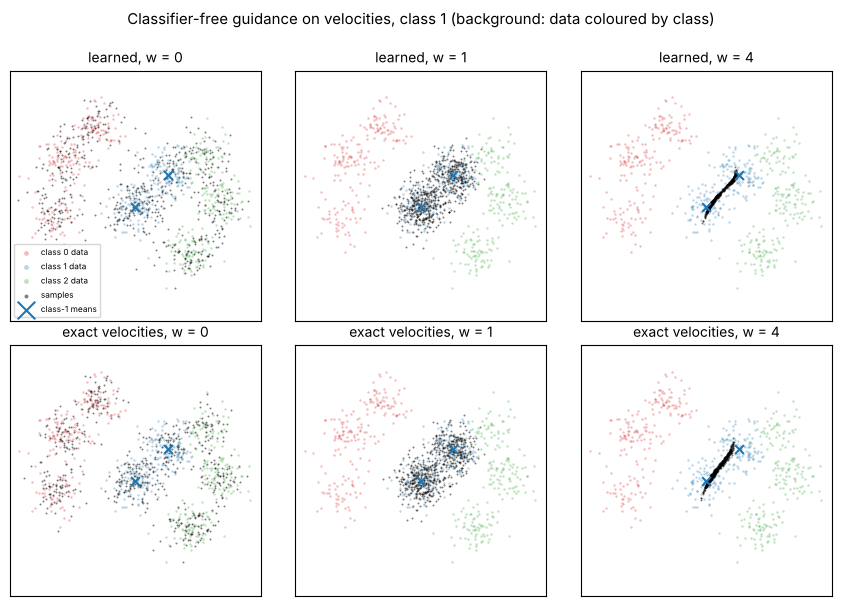

                  |   w | std across the class-1 axis | fraction within 1 std of a class-1 mean
 exact velocities |   0 |                       1.487 | 0.14
 exact velocities |   1 |                       0.331 | 0.40
 exact velocities |   4 |                       0.073 | 0.65
          learned |   0 |                       1.504 | 0.10
          learned |   1 |                       0.334 | 0.38
          learned |   4 |                       0.052 | 0.75
(component std = 0.35; the 'axis' is the line through the two class-1 means)


In [27]:
target = 1                                              # the central, ambiguous class
oracle_c = lgmm.subset(np.where(comp_class == target)[0])   # exact class-conditional distribution


def exact_guided_vfn(w):
    """The same guidance rule applied to the exact unconditional and class-conditional velocities."""
    def vfn(x, t):
        v_u = exact_velocity(lgmm, x, t)[0]
        return v_u + w * (exact_velocity(oracle_c, x, t)[0] - v_u)
    return vfn


def guidance_stats(xs, means, std):
    """Spread perpendicular to the line through the two class means, and fraction within 1 std of a mean."""
    xs, means = xs.detach().cpu().double(), means.double()
    d = (means[1] - means[0]) / (means[1] - means[0]).norm()
    perp = (xs - means[0]) @ torch.stack([-d[1], d[0]])          # signed distance from the line
    near = (torch.cdist(xs, means).min(1).values < std).double().mean()
    return perp.std().item(), near.item()


ws = [0.0, 1.0, 4.0]
class_cols = np.array(["tab:red", "tab:blue", "tab:green"])
x_bg, y_bg = x_lab[:N_PLOT].cpu(), y_lab[:N_PLOT].cpu().numpy()
comp_std = math.sqrt(oracle_c.covs[0, 0, 0].item())               # isotropic components
fig, axes = plt.subplots(2, len(ws), figsize=(2.9 * len(ws), 6.0))
rows = []                                                         # summary statistics, printed below the figure
for j, w in enumerate(ws):
    for i, (name, vfn) in enumerate([("learned", guided_vfn(cond_model, target, w)),
                                     ("exact velocities", exact_guided_vfn(w))]):
        xs = ode_sample(vfn, x1_eval[:N_PLOT], 32)
        ax = axes[i, j]
        for c in range(3):
            dm.scatter2d(x_bg[torch.as_tensor(y_bg == c)], ax=ax, c=class_cols[c], s=3, alpha=0.3, lim=3.5, label=f"class {c} data")
        dm.scatter2d(xs, ax=ax, c="k", s=2, alpha=0.5, lim=3.5, title=f"{name}, w = {w:g}", label="samples")
        ax.scatter(oracle_c.means[:, 0], oracle_c.means[:, 1], marker="x", s=40, c="tab:blue", linewidths=1.5,
                   zorder=4, label="class-1 means")
        rows.append((name, w, *guidance_stats(xs, oracle_c.means.float(), comp_std)))
axes[0, 0].legend(loc="lower left", fontsize=6, markerscale=2)
plt.suptitle(f"Classifier-free guidance on velocities, class {target} (background: data coloured by class)", y=1.0)
plt.tight_layout()
plt.show()
print(f"{'':>17} | {'w':>3} | std across the class-1 axis | fraction within 1 std of a class-1 mean")
for name, w, perp_std, near in sorted(rows, key=lambda r: r[0]):
    print(f"{name:>17} | {w:3g} | {perp_std:27.3f} | {near:.2f}")
print(f"(component std = {comp_std:.2f}; the 'axis' is the line through the two class-1 means)")

Top row: the trained conditional flow; bottom row: the same guidance rule applied to the exact
conditional and unconditional velocities — the two rows agree closely. $w=0$ gives the unconditional
mixture and $w=1$ the class-1 distribution. For $w>1$ samples are pushed away from everything the other
classes could explain. At large $w$ the diversity collapses in the direction that separates class 1 from
classes 0 and 2: the samples lie on a thin curve running along the axis through the two class-1
components (the table shows the spread across that axis shrinking far below the component width, while
*more* samples end up near a class-1 mean than at $w=1$). Guidance sharpens $p(y=1\mid x)$, i.e. it seeks
points that are unambiguously class 1, rather than sampling $p(x\mid y=1)$ more faithfully. Guidance is a heuristic:
the guided field is not the velocity of the noised version of any fixed target distribution, which is
why strong guidance distorts samples (notebook 06, Section 4, analyses this for scores; since guiding
$v$ is literally the same operation, the same analysis applies).

## Exercises

**Exercise 1 (timestep distribution).** Retrain the flow model with SD3's logit-normal timesteps,
`t_sampler=lambda bs, dev: torch.sigmoid(torch.randn(bs, device=dev))`, and recompute
`velocity_error_vs_t` and the MMD-vs-NFE curve. *Predict first:* at which $t$ should the error go down,
and where up?
<details><summary>Hint / solution</summary>
The minimiser is unchanged (Section 5), so only the allocation of the network's errors moves.
The logit-normal puts few samples near $t=0$ and $t=1$, so errors drop in the middle and rise at the ends —
mostly near $t\to0$, where the field is sharpest. For this 2-D mixture with thin components, fine detail
near the data matters, so uniform sampling may well be as good or better; in high-resolution images the
ends are "easy" and the middle carries the perceptually relevant structure, which is why SD3 prefers it.
</details>

**Exercise 2 (non-uniform sampling grids).** Pass an explicit grid to `ode_sample(..., ts=...)` using the SD3
shift $t\mapsto st/(1+(s-1)t)$ applied to a uniform grid, for $s\in\{1/3, 1/2, 1, 2, 3\}$, and compare MMD at 4 and 8
Euler steps for `fm_model` *and* for `exact_vfn(gmm)` (which isolates discretisation error). *Predict first:*
which $s$ wins?
<details><summary>Hint / solution</summary>
`u = np.linspace(1, 0, n + 1); ts = s * u / (1 + (s - 1) * u)`. $s>1$ spends more steps at high noise,
$s<1$ more near the data. On this 2-D mixture the uniform grid ($s=1$) is at or near the best, and strong shifts
in *either* direction hurt, for the learned and the exact field alike (a mild shift towards the data,
$s\approx0.7$, may help slightly at 8–16 steps). With $s=1/3$ the first step is huge, and a large step from $t=1$
collapses particles towards the data mean ($v(x,1)=x-\mathbb E[x_0]$); with $s=3$ the last step is huge, and it
lands on a blurry posterior mean $\hat x_0$. SD3's shift $s>1$ is motivated by high-resolution images, where
more pixels make the same $t$ effectively less noisy, not by 2-D toys.
</details>

**Exercise 3 (reflow again).** Generate new pairs with `rf_model` and train a 3-rectified flow. Does
straightness keep improving? What happens to the MMD at 64 NFE compared with the 1- and 2-rectified flows?
<details><summary>Hint / solution</summary>
Straightness improves with diminishing returns (Liu et al. show the sum of straightness over reflows is bounded).
The many-step MMD cannot improve and usually degrades slightly: each reflow trains on samples of the previous
model, so its errors accumulate.
</details>

**Exercise 4 (OT batch size and dimension).** Retrain OT-CFM with `bs=16` and `bs=1024` and compare
straightness. Then embed the data in $d=16$ dimensions (append 14 coordinates of small Gaussian noise;
add a `data_dim` argument to `make_mlp`, and draw new 16-D noise for `x1_path` / `x1_eval`) and repeat.
How does the benefit of OT pairing change?
<details><summary>Hint / solution</summary>
Larger batches approximate the OT plan better, giving straighter paths. In higher dimension a batch of fixed size
covers the space much more sparsely, the mini-batch plan is far from the population OT plan, and the gain
shrinks — the reason OT-CFM shines on low-dimensional problems.
</details>

**Exercise 5 (flow matching on MNIST, GPU recommended).** Train `dm.UNet(**dm.MNIST_RECIPE)` with `train_flow`
on `dm.load_mnist()[0]` (images in $[-1,1]$). One change is needed: broadcast $t$ over channels and pixels
(`t[:, None, None, None]`); `time_input` stays as it is. Sample with 20–50 Euler steps and `dm.show_images`.
<details><summary>Hint / solution</summary>
In `train_flow` replace both `t[:, None]` with `t.view(-1, *[1] * (x0.dim() - 1))`. A few thousand steps at batch 128
give recognisable digits on a GPU. You can then wrap the model with a 4-D version of `FlowAsEps` and use
`dm.ddim_sample` to compare samplers, exactly as in Section 5.
</details>

**Exercise 6 (head vs weighting).** Section 5 could not separate the output head from the loss weighting.
Do it here, on the flow path with $t\sim U(0,1)$ clamped to $t\le t_{\max}=0.98$ (the conversion below divides by
$1-t$). Train `make_mlp()` as an **$\varepsilon$-head** with (a) the plain $\varepsilon$-MSE, `F.mse_loss(out, eps)`, and
(b) the flow-matching loss written for an $\varepsilon$-head, `F.mse_loss((out - xt) / (1 - t[:, None]), eps - x0)`.
Turn each into a velocity field with $v=(\hat\varepsilon-x)/(1-t)$ (clamping $t$ in the same way), then compare
`velocity_error_vs_t` and MMD vs Euler NFE with `fm_model`. *Predict first:* which of (a) and (b) shows the
blow-up near $t=1$?
<details><summary>Hint / solution</summary>
Copy `train_flow`, add `t = t.clamp(max=0.98)` and change only the loss line. Velocity wrapper:
`lambda x, t: (m(x, torch.full((len(x),), time_input(min(t, 0.98)), device=x.device)) - x) / (1 - min(t, 0.98))`.
(a) reproduces the DDPM pattern, even though it uses the flow path and time distribution: it is accurate near
the data, but its velocity error explodes as $t\to1$ and its fewest-step samples are the worst of the three. So
the near-noise blow-up comes from the *weighting* (that region gets almost no attention). (b) is the same
objective as `fm_model`, only with a different output layer: the near-noise blow-up is gone, but it is less
accurate near the data than the other two, most likely because a few near-noise samples with weights up to
$1/(1-t_{\max})^2=2500$ dominate every gradient. Try $t_{\max}=0.9$ and $0.995$: it gets better as $t_{\max}$ drops
and much worse as it approaches 1. Expect the differences at 8–16 NFE to be modest (check a second seed).
Neither variant matches the $v$-head everywhere, which is why "$v$-prediction" and "flow-matching weighting"
come as a package in practice: the $v$-head is the parametrisation in which that weighting is well conditioned.
</details>

## Key takeaways

* Flow matching learns a velocity field $v(x,t)=\mathbb E[\varepsilon-x_0\mid x_t=x]$ whose ODE transports noise to data;
  it satisfies the continuity equation for the interpolation path $x_t=(1-t)x_0+t\varepsilon$.
* Regressing on the per-pair velocity $\varepsilon - x_0$ has the same gradients as regressing on the marginal velocity;
  the loss plateaus at the average posterior variance, not at zero.
* $v = (x_t-\hat x_0)/t$: the velocity is a posterior mean, and $\hat x_0 = x_t - tv$, $\hat\varepsilon = x_t+(1-t)v$ convert it to
  diffusion's predictions. A VP diffusion state is a flow state after rescaling by $\alpha+\sigma$, and DDIM is Euler in flow coordinates.
* The differences between "flow" and "diffusion" models are the time parametrisation, the output parametrisation and the
  loss weighting over noise levels — real, practical differences, but not different models.
* Marginal flows are curved because many pairs pass through the same $(x,t)$ with different velocities and the field
  averages them; straighter couplings (reflow, mini-batch OT) make 1–2-step sampling work.
* The timestep distribution and loss weighting never change the minimiser (the posterior mean); they decide where a
  finite network's errors end up, and with which parametrisation the objective is well conditioned.
* Euler with 20–50 steps, a logit-normal/shifted timestep distribution and CFG on velocities is the large-scale recipe.

## Further reading

* Lipman, Chen, Ben-Hamu, Nickel, Le (2023). *Flow Matching for Generative Modeling.* arXiv:2210.02747.
* Liu, Gong, Liu (2023). *Flow Straight and Fast: Learning to Generate and Transfer Data with Rectified Flow.* arXiv:2209.03003.
* Albergo, Vanden-Eijnden (2023). *Building Normalizing Flows with Stochastic Interpolants.* arXiv:2209.15571.
* Tong et al. (2023). *Improving and Generalizing Flow-Based Generative Models with Minibatch Optimal Transport.* arXiv:2302.00482.
* Pooladian et al. (2023). *Multisample Flow Matching: Straightening Flows with Minibatch Couplings.* ICML 2023. arXiv:2304.14772.
* Esser et al. (2024). *Scaling Rectified Flow Transformers for High-Resolution Image Synthesis* (Stable Diffusion 3). arXiv:2403.03206.
* Song et al. (2021). *Score-Based Generative Modeling through Stochastic Differential Equations* (probability-flow ODE). arXiv:2011.13456.
* Song, Meng, Ermon (2021). *Denoising Diffusion Implicit Models.* arXiv:2010.02502.
* Salimans, Ho (2022). *Progressive Distillation for Fast Sampling of Diffusion Models* (v-prediction). arXiv:2202.00512.
* Karras, Aittala, Aila, Laine (2022). *Elucidating the Design Space of Diffusion-Based Generative Models.* arXiv:2206.00364.
* Kingma, Gao (2023). *Understanding Diffusion Objectives as the ELBO with Simple Data Augmentation.* NeurIPS 2023. arXiv:2303.00848.
* Ho, Salimans (2022). *Classifier-Free Diffusion Guidance.* arXiv:2207.12598.
* Song, Dhariwal, Chen, Sutskever (2023). *Consistency Models.* arXiv:2303.01469.
* Sauer, Lorenz, Blattmann, Rombach (2023). *Adversarial Diffusion Distillation* (SDXL-Turbo). arXiv:2311.17042.
* Vincent (2011). *A Connection Between Score Matching and Denoising Autoencoders.* Neural Computation.
* Applications mentioned in Section 8: Liu et al. (2024), *InstaFlow: One Step is Enough for High-Quality Diffusion-Based
  Text-to-Image Generation*, arXiv:2309.06380; Le et al. (2023), *Voicebox: Text-Guided Multilingual Universal Speech
  Generation at Scale*, arXiv:2306.15687; Polyak et al. (2024), *Movie Gen: A Cast of Media Foundation Models*,
  arXiv:2410.13720; Black et al. (2024), *$\pi_0$: A Vision-Language-Action Flow Model for General Robot Control*, arXiv:2410.24164.